In [3]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


/home/lihaoxing/tmp/ipykernel_995387/3940551965.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_995387/3940551965.py:35: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:4.633e-01 U_stat=1.650e+01
WT vs. GATA6-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.948e-01 U_stat=1.800e+01
WT vs. CXCL16-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:5.296e-01 U_stat=1.600e+01
WT vs. ZC3H12A-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:6.723e-01 U_stat=1.000e+01


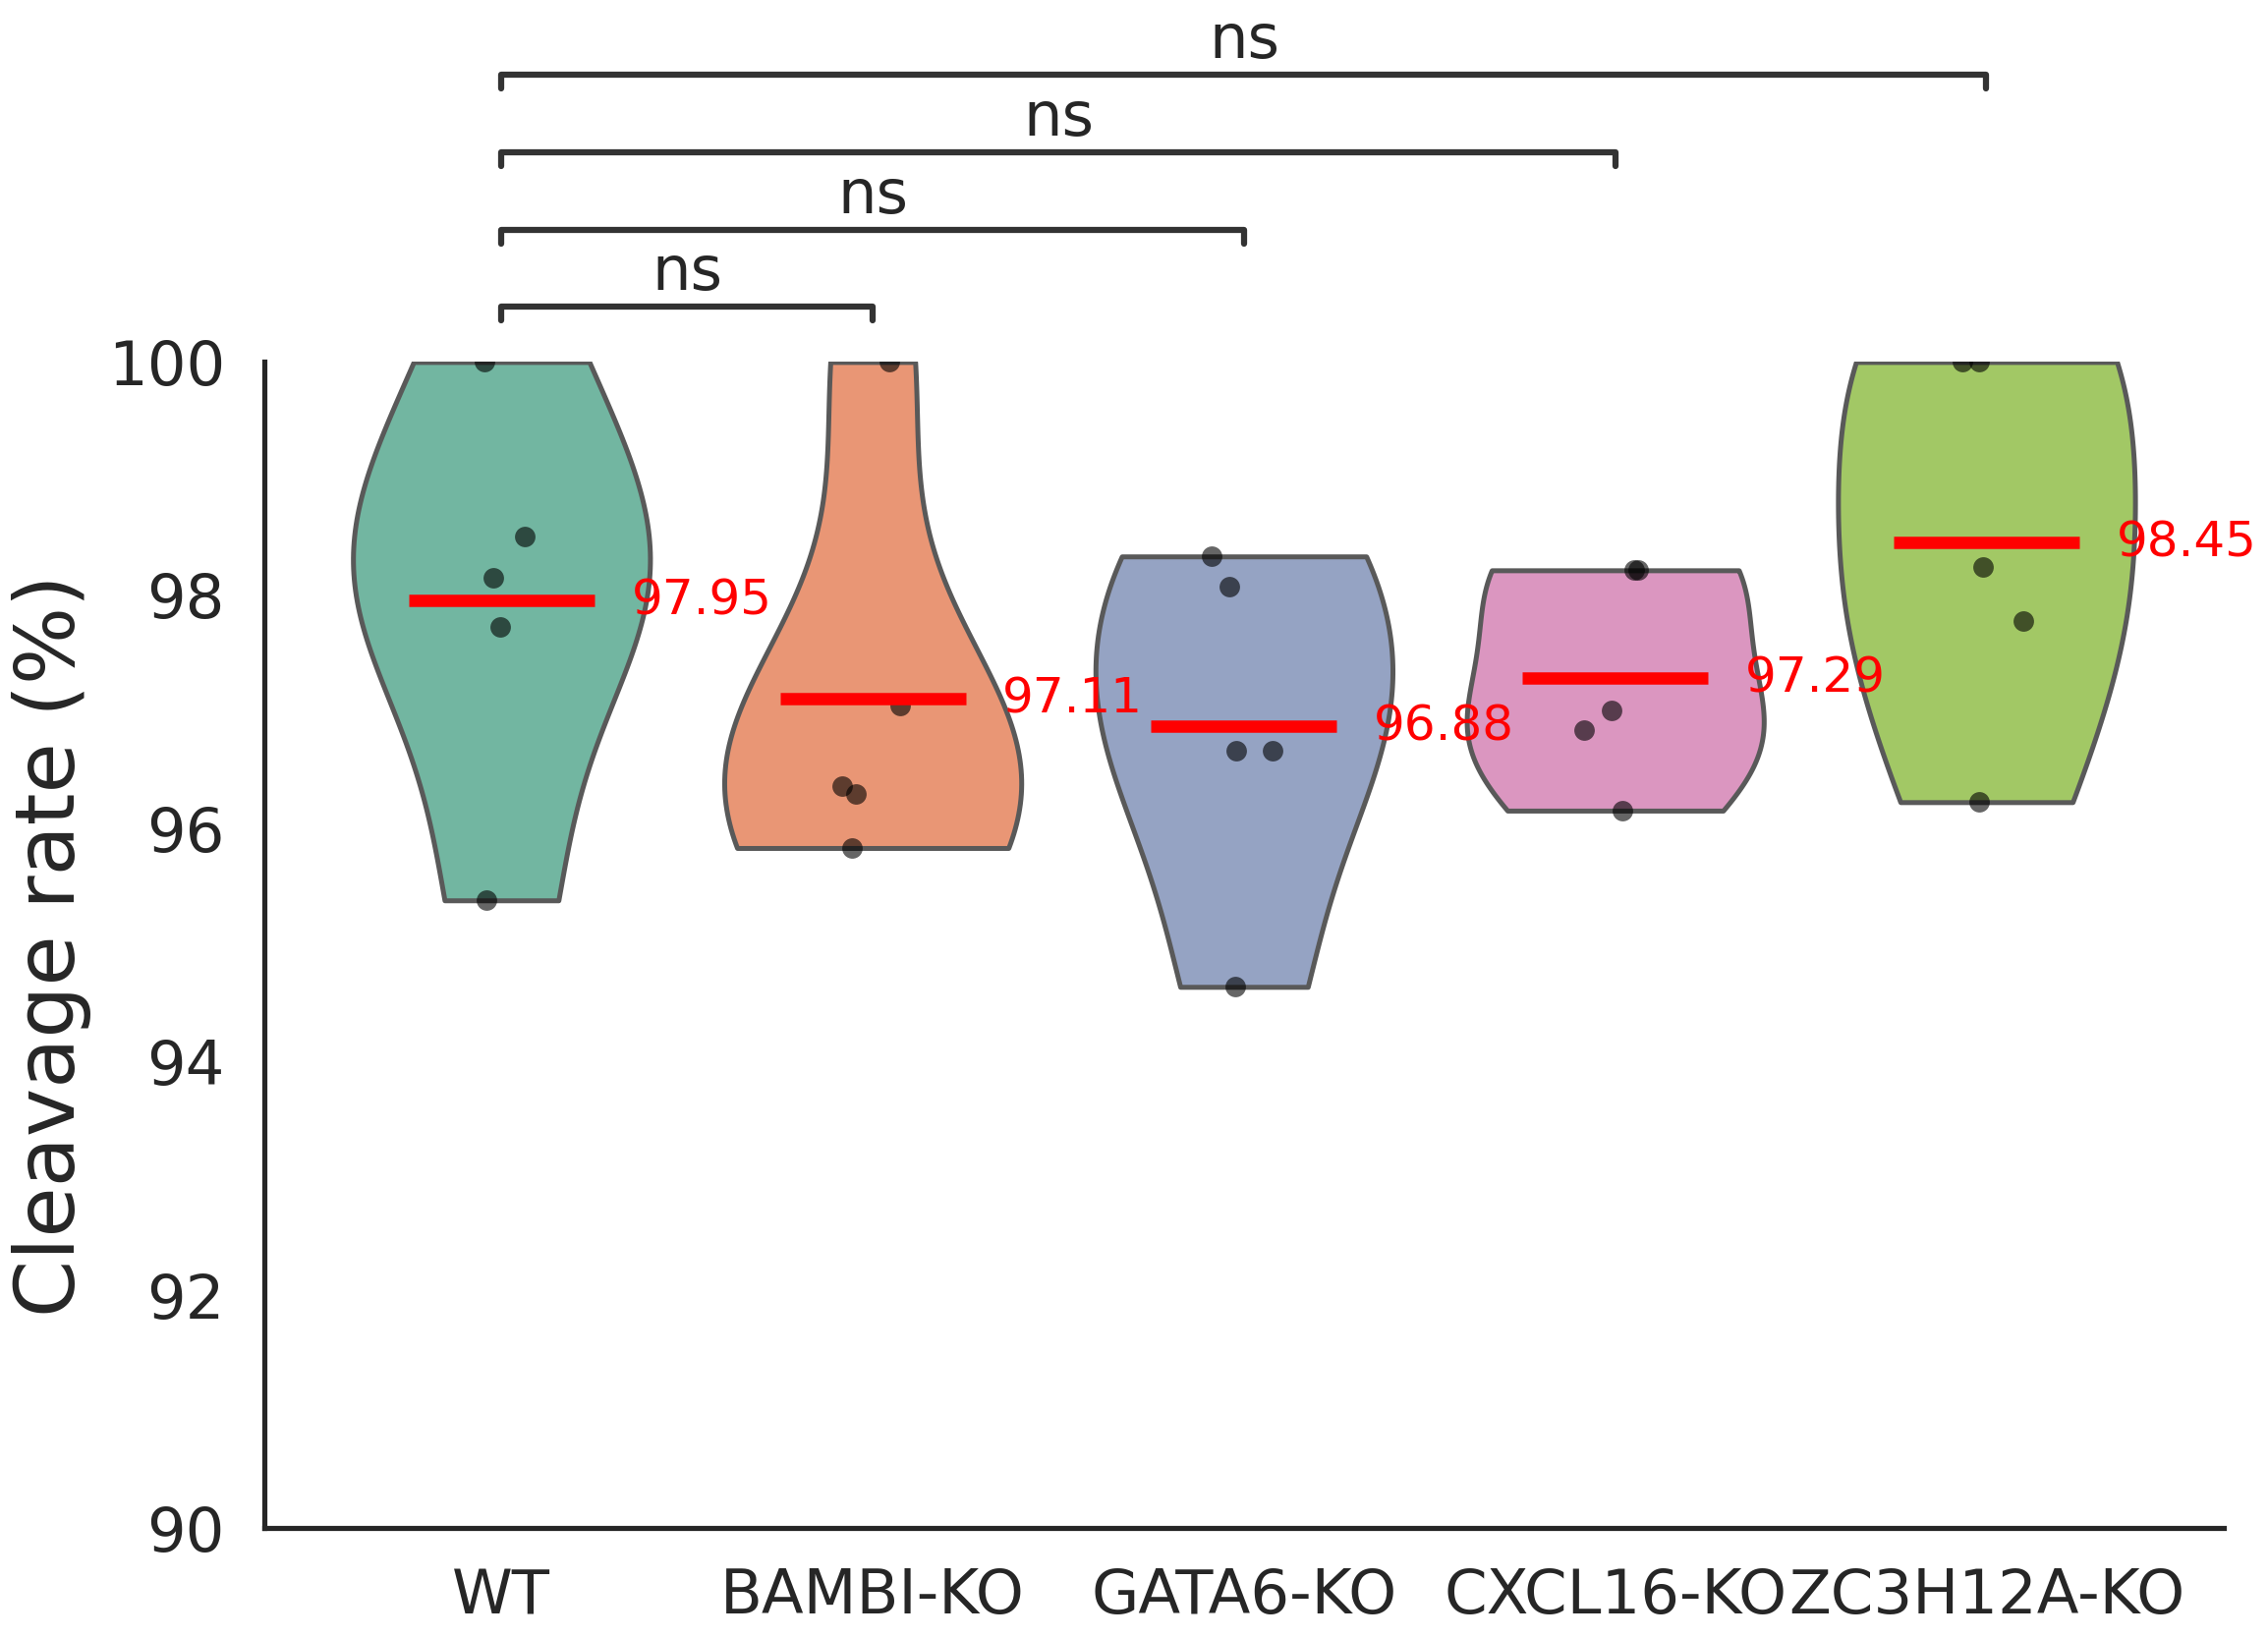

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

# ================================
# 基础设置（无网格，DejaVu Sans）
# ================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")          # 白色背景，无网格

plt.rcParams['axes.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15

# ================================
# 读取数据
# ================================
df = pd.read_csv("5次重复卵裂率统计.txt", sep="\t")
df.columns = ["treatment", "cleavage_rate", "reps"]
df["cleavage_rate"] = df["cleavage_rate"] * 100

order = ["WT", "BAMBI-KO", "GATA6-KO", "CXCL16-KO", "ZC3H12A-KO"]

# ================================
# 绘图
# ================================
fig, ax = plt.subplots(figsize=(8, 6))

# ---- 小提琴（无内部箱线） ----
sns.violinplot(
    data=df,
    x="treatment",
    y="cleavage_rate",
    order=order,
    palette="Set2",
    inner=None,                # 不画四分线
    cut=0,
    scale="width",
    linewidth=1.2,
    ax=ax
)

# ---- 黑色散点 ----
sns.stripplot(
    data=df,
    x="treatment",
    y="cleavage_rate",
    color='black',
    size=5,
    alpha=0.6,
    order=order,
    ax=ax
)

# ---- 红色均值线 + 数值 ----
group_means = df.groupby("treatment")["cleavage_rate"].mean()
for i, g in enumerate(order):
    mean_val = group_means[g]
    ax.hlines(y=mean_val, xmin=i-0.25, xmax=i+0.25,
              color='red', linewidth=3, zorder=5)
    ax.text(i + 0.35, mean_val, f"{mean_val:.2f}",
            ha='left', va='center', fontsize=12, color='red')

# ================================
# 统计检验（Mann-Whitney，星号画在内部）
# ================================
pairs = [("WT", g) for g in order if g != "WT"]
annotator = Annotator(ax, pairs, data=df, x="treatment", y="cleavage_rate", order=order)
annotator.configure(test='Mann-Whitney',
                    text_format='star',
                    loc='inside',        # 星号在箱体内部
                    fontsize=15)
annotator.apply_and_annotate()

# ================================
# 坐标轴美化（固定 y 轴上限=100，去掉偏移）
# ================================
ax.set_ylabel("Cleavage rate (%)", fontsize=20)
ax.set_xlabel("", fontsize=20)

# 固定 y 轴范围：下限留 90 给散点，上限恰好 100
ax.set_ylim(90, 100)
ax.set_yticks([90, 92, 94, 96, 98, 100])   # 可根据数据调整

# 只隐藏上、右脊线，保留左下角完整连接（无偏移）
sns.despine(top=True, right=True, left=False, bottom=False)
# 或者直接设置 spines
# ax.spines['top'].set_visible(False)
# ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("Cleavage_rate_fixed_axis.svg", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

/home/lihaoxing/tmp/ipykernel_995387/2386321454.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_995387/2386321454.py:43: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:4.633e-01 U_stat=1.650e+01
WT vs. GATA6-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.948e-01 U_stat=1.800e+01
WT vs. CXCL16-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:5.296e-01 U_stat=1.600e+01
WT vs. ZC3H12A-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:6.723e-01 U_stat=1.000e+01
WT vs. 2C-ZSCAN4-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.595e-01 U_stat=1.000e+00


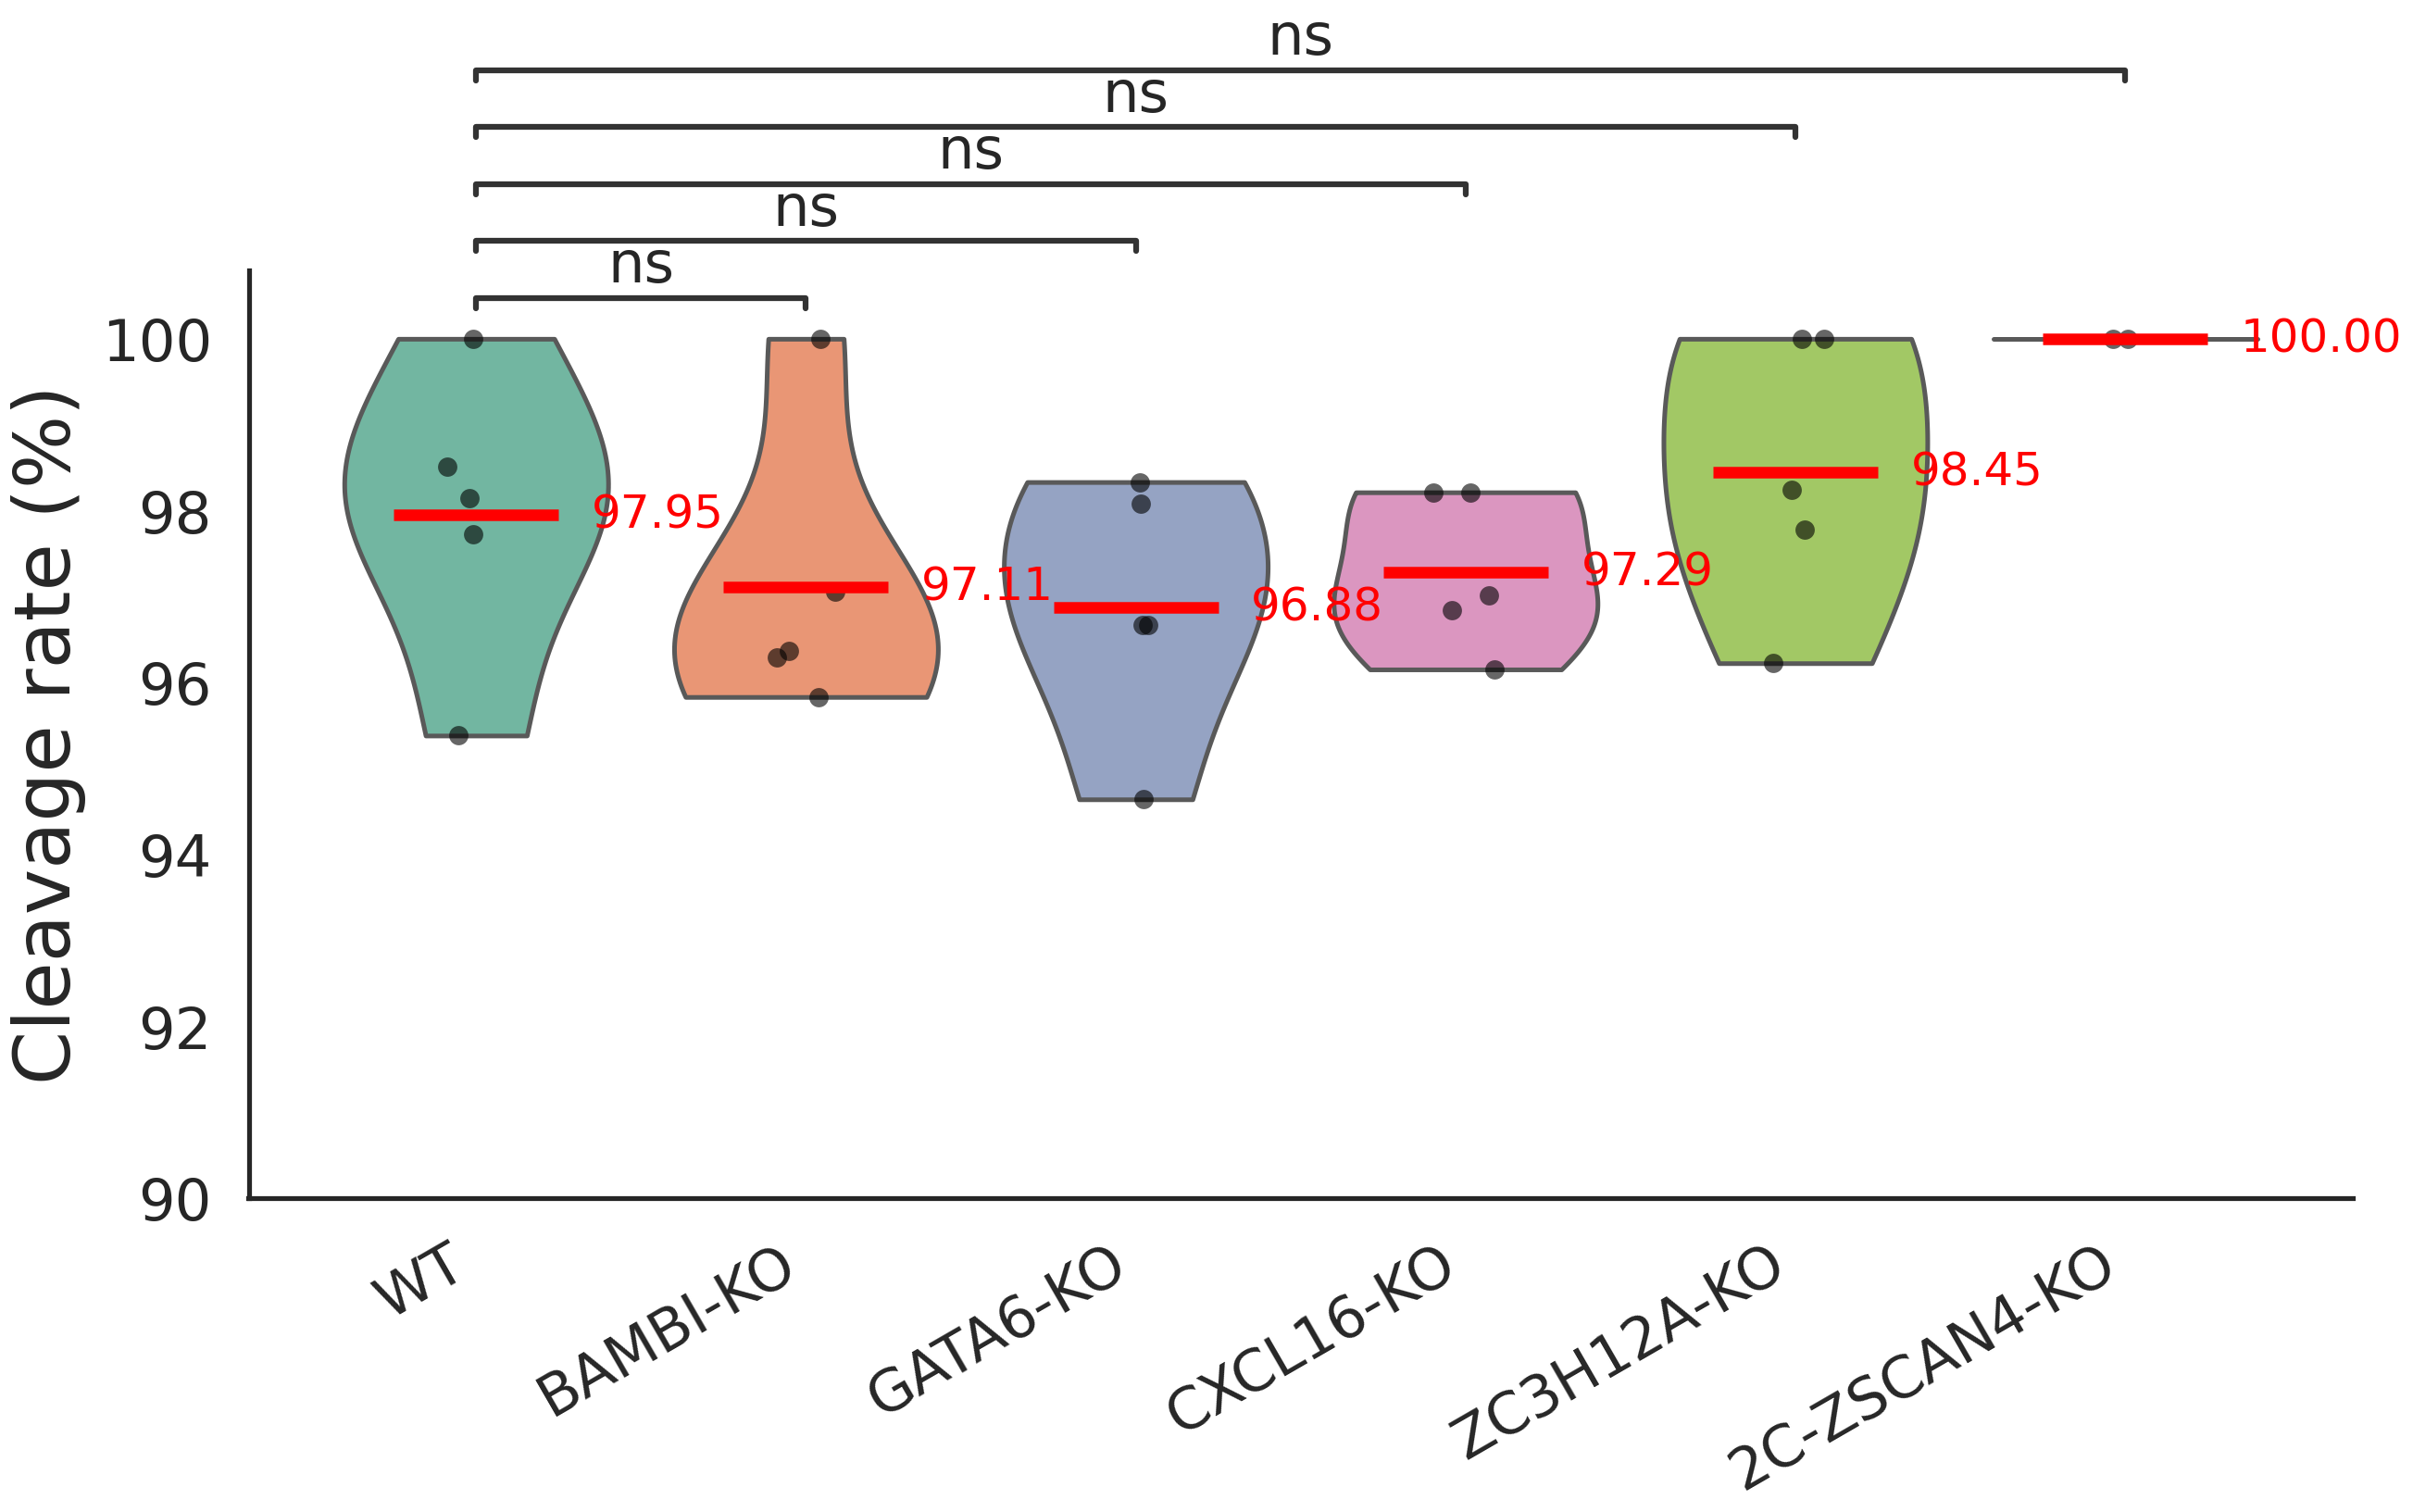

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

# ================================
# 基础设置（无网格，DejaVu Sans）
# ================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")          # 白色背景，无网格

plt.rcParams['axes.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15

# ================================
# 读取数据
# ================================
df = pd.read_csv("5次重复卵裂率统计.txt", sep="\t")
df.columns = ["treatment", "cleavage_rate", "reps"]
df["cleavage_rate"] = df["cleavage_rate"] * 100

# ---- 新增 2C-ZSCAN4-KO 组（2 个重复，均为 100%）----
extra = pd.DataFrame({
    "treatment":    ["2C-ZSCAN4-KO", "2C-ZSCAN4-KO"],
    "cleavage_rate": [100.0, 100.0],
    "reps":          [1, 2],
})
df = pd.concat([df, extra], ignore_index=True)

order = ["WT", "BAMBI-KO", "GATA6-KO", "CXCL16-KO", "ZC3H12A-KO", "2C-ZSCAN4-KO"]

# ================================
# 绘图
# ================================
fig, ax = plt.subplots(figsize=(9, 6))

# ---- 小提琴（无内部箱线） ----
sns.violinplot(
    data=df,
    x="treatment",
    y="cleavage_rate",
    order=order,
    palette="Set2",
    inner=None,                # 不画四分线
    cut=0,
    scale="width",
    linewidth=1.2,
    ax=ax
)

# ---- 黑色散点 ----
sns.stripplot(
    data=df,
    x="treatment",
    y="cleavage_rate",
    color='black',
    size=5,
    alpha=0.6,
    order=order,
    ax=ax
)

# ---- 红色均值线 + 数值 ----
group_means = df.groupby("treatment")["cleavage_rate"].mean()
for i, g in enumerate(order):
    mean_val = group_means[g]
    ax.hlines(y=mean_val, xmin=i-0.25, xmax=i+0.25,
              color='red', linewidth=3, zorder=5)
    ax.text(i + 0.35, mean_val, f"{mean_val:.2f}",
            ha='left', va='center', fontsize=12, color='red')

# ================================
# 统计检验（Mann-Whitney，星号画在内部）
# 注意：2C-ZSCAN4-KO 组 n=2，Mann-Whitney 检验效能很低，
#       结果仅作参考；如需严格统计，建议补充重复数后再检验。
# ================================
pairs = [("WT", g) for g in order if g != "WT"]
annotator = Annotator(ax, pairs, data=df, x="treatment", y="cleavage_rate", order=order)
annotator.configure(test='Mann-Whitney',
                    text_format='star',
                    loc='inside',        # 星号在箱体内部
                    fontsize=15)
annotator.apply_and_annotate()

# ================================
# 坐标轴美化（去掉偏移，给 100% 点留出上边距）
# ================================
ax.set_ylabel("Cleavage rate (%)", fontsize=20)
ax.set_xlabel("", fontsize=20)

# 上限设为 100.8，避免 100% 的点和均值文字被上边框裁切
ax.set_ylim(90, 100.8)
ax.set_yticks([90, 92, 94, 96, 98, 100])

# 只隐藏上、右脊线，保留左下角完整连接（无偏移）
sns.despine(top=True, right=True, left=False, bottom=False)

# x 轴标签过长时适当旋转，避免重叠
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.savefig("Cleavage_rate_fixed_axis.svg", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

/home/lihaoxing/tmp/ipykernel_439334/3239753275.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_439334/3239753275.py:35: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: t-test paired samples, P_val:2.403e-02 t=3.539e+00
WT vs. GATA6-KO: t-test paired samples, P_val:2.434e-02 t=3.525e+00
WT vs. CXCL16-KO: t-test paired samples, P_val:3.939e-02 t=3.014e+00
WT vs. ZC3H12A-KO: t-test paired samples, P_val:5.159e-01 t=7.118e-01


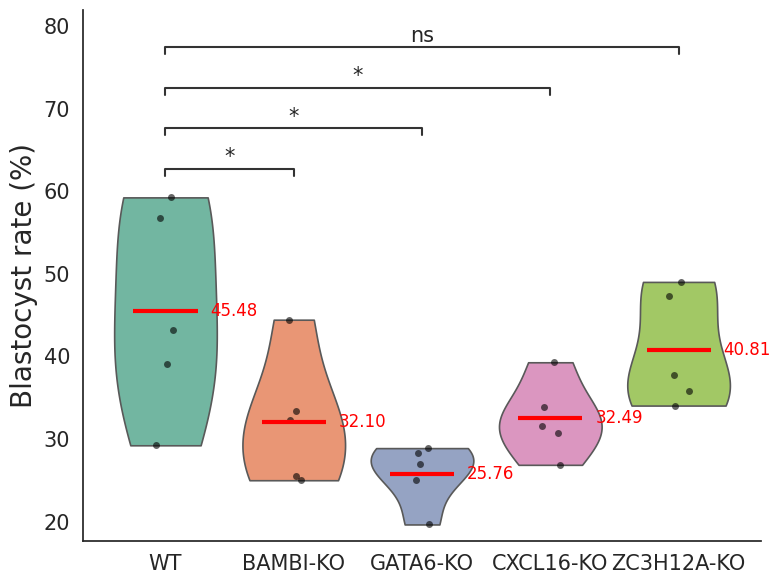

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

# ================================
# 基础设置（无网格，DejaVu Sans）
# ================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")          # 白色背景，无网格

plt.rcParams['axes.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15

# ================================
# 读取数据（宽格式转长格式）
# ================================
df = pd.read_csv("5次重复囊胚率统计.txt", sep="\t")
df_melt = df.melt(var_name="Group", value_name="Value")
df_melt["Value"] = df_melt["Value"] * 100   # 转成百分比

order = ["WT", "BAMBI-KO", "GATA6-KO", "CXCL16-KO", "ZC3H12A-KO"]

# ================================
# 绘图
# ================================
fig, ax = plt.subplots(figsize=(8, 6))

# ---- 小提琴（无内部箱线） ----
sns.violinplot(
    data=df_melt,
    x="Group",
    y="Value",
    order=order,
    palette="Set2",
    inner=None,                # 不画四分线
    cut=0,
    scale="width",
    linewidth=1.2,
    ax=ax
)

# ---- 黑色散点 ----
sns.stripplot(
    data=df_melt,
    x="Group",
    y="Value",
    color='black',
    size=5,
    alpha=0.6,
    order=order,
    ax=ax
)

# ---- 红色均值线 + 数值 ----
group_means = df_melt.groupby("Group")["Value"].mean()
for i, g in enumerate(order):
    mean_val = group_means[g]
    ax.hlines(y=mean_val, xmin=i-0.25, xmax=i+0.25,
              color='red', linewidth=3, zorder=5)
    ax.text(i + 0.35, mean_val, f"{mean_val:.2f}",
            ha='left', va='center', fontsize=12, color='red')

# ================================
# 统计检验（Mann-Whitney，星号在内部）
# ================================
pairs = [("WT", g) for g in order if g != "WT"]
annotator = Annotator(ax, pairs, data=df_melt, x="Group", y="Value", order=order)
annotator.configure(test='t-test_paired',   # 非参数检验
                    text_format='star',
                    loc='inside',          # 星号画在箱体内部
                    fontsize=15)
annotator.apply_and_annotate()

# ================================
# 坐标轴美化（固定 y 轴上限=100，无偏移）
# ================================
ax.set_ylabel("Blastocyst rate (%)", fontsize=20)
ax.set_xlabel("", fontsize=20)

# 固定 y 轴范围：上限正好100，下限根据数据调整（此处设为85给散点留空间）
#ax.set_ylim(85, 100)
#ax.set_yticks([85, 90, 95, 100])   # 可根据需要增减

# 只隐藏上、右脊线，保留左下角完整连接（无偏移）
sns.despine(top=True, right=True, left=False, bottom=False)

plt.tight_layout()
plt.savefig('Blastocyst_rate_style_updated.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

/home/lihaoxing/tmp/ipykernel_440550/1416469934.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_440550/1416469934.py:29: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:5.090e-01 U_stat=2.076e+03
WT vs. GATA6-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.187e-01 U_stat=1.995e+03
WT vs. CXCL16-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.623e-01 U_stat=2.447e+03
WT vs. ZC3H12A-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.784e-04 U_stat=1.250e+03
WT vs. ZSCAN4-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.365e-01 U_stat=7.875e+02


/home/lihaoxing/tmp/ipykernel_440550/1416469934.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_440550/1416469934.py:29: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:7.122e-01 U_stat=1.868e+03
WT vs. GATA6-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:7.568e-01 U_stat=1.651e+03
WT vs. CXCL16-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.861e-02 U_stat=2.656e+03
WT vs. ZC3H12A-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:7.403e-02 U_stat=1.042e+03
WT vs. ZSCAN4-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.343e-02 U_stat=9.155e+02


/home/lihaoxing/tmp/ipykernel_440550/1416469934.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_440550/1416469934.py:29: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:7.589e-01 U_stat=1.880e+03
WT vs. GATA6-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:8.662e-01 U_stat=1.677e+03
WT vs. CXCL16-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.623e-02 U_stat=2.666e+03
WT vs. ZC3H12A-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.665e-02 U_stat=1.090e+03
WT vs. ZSCAN4-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.612e-02 U_stat=9.090e+02


... (2 outputs left out)

/home/lihaoxing/tmp/ipykernel_440550/1416469934.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_440550/1416469934.py:29: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.374e-01 U_stat=1.704e+03
WT vs. GATA6-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.844e-02 U_stat=1.306e+03
WT vs. CXCL16-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:7.574e-01 U_stat=2.076e+03
WT vs. ZC3H12A-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.918e-03 U_stat=4.840e+02
WT vs. ZSCAN4-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.542e-01 U_stat=7.835e+02


/home/lihaoxing/tmp/ipykernel_440550/1416469934.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_440550/1416469934.py:29: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.374e-01 U_stat=2.182e+03
WT vs. GATA6-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.844e-02 U_stat=2.112e+03
WT vs. CXCL16-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:7.574e-01 U_stat=2.212e+03
WT vs. ZC3H12A-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.918e-03 U_stat=1.191e+03
WT vs. ZSCAN4-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:4.736e-01 U_stat=5.985e+02


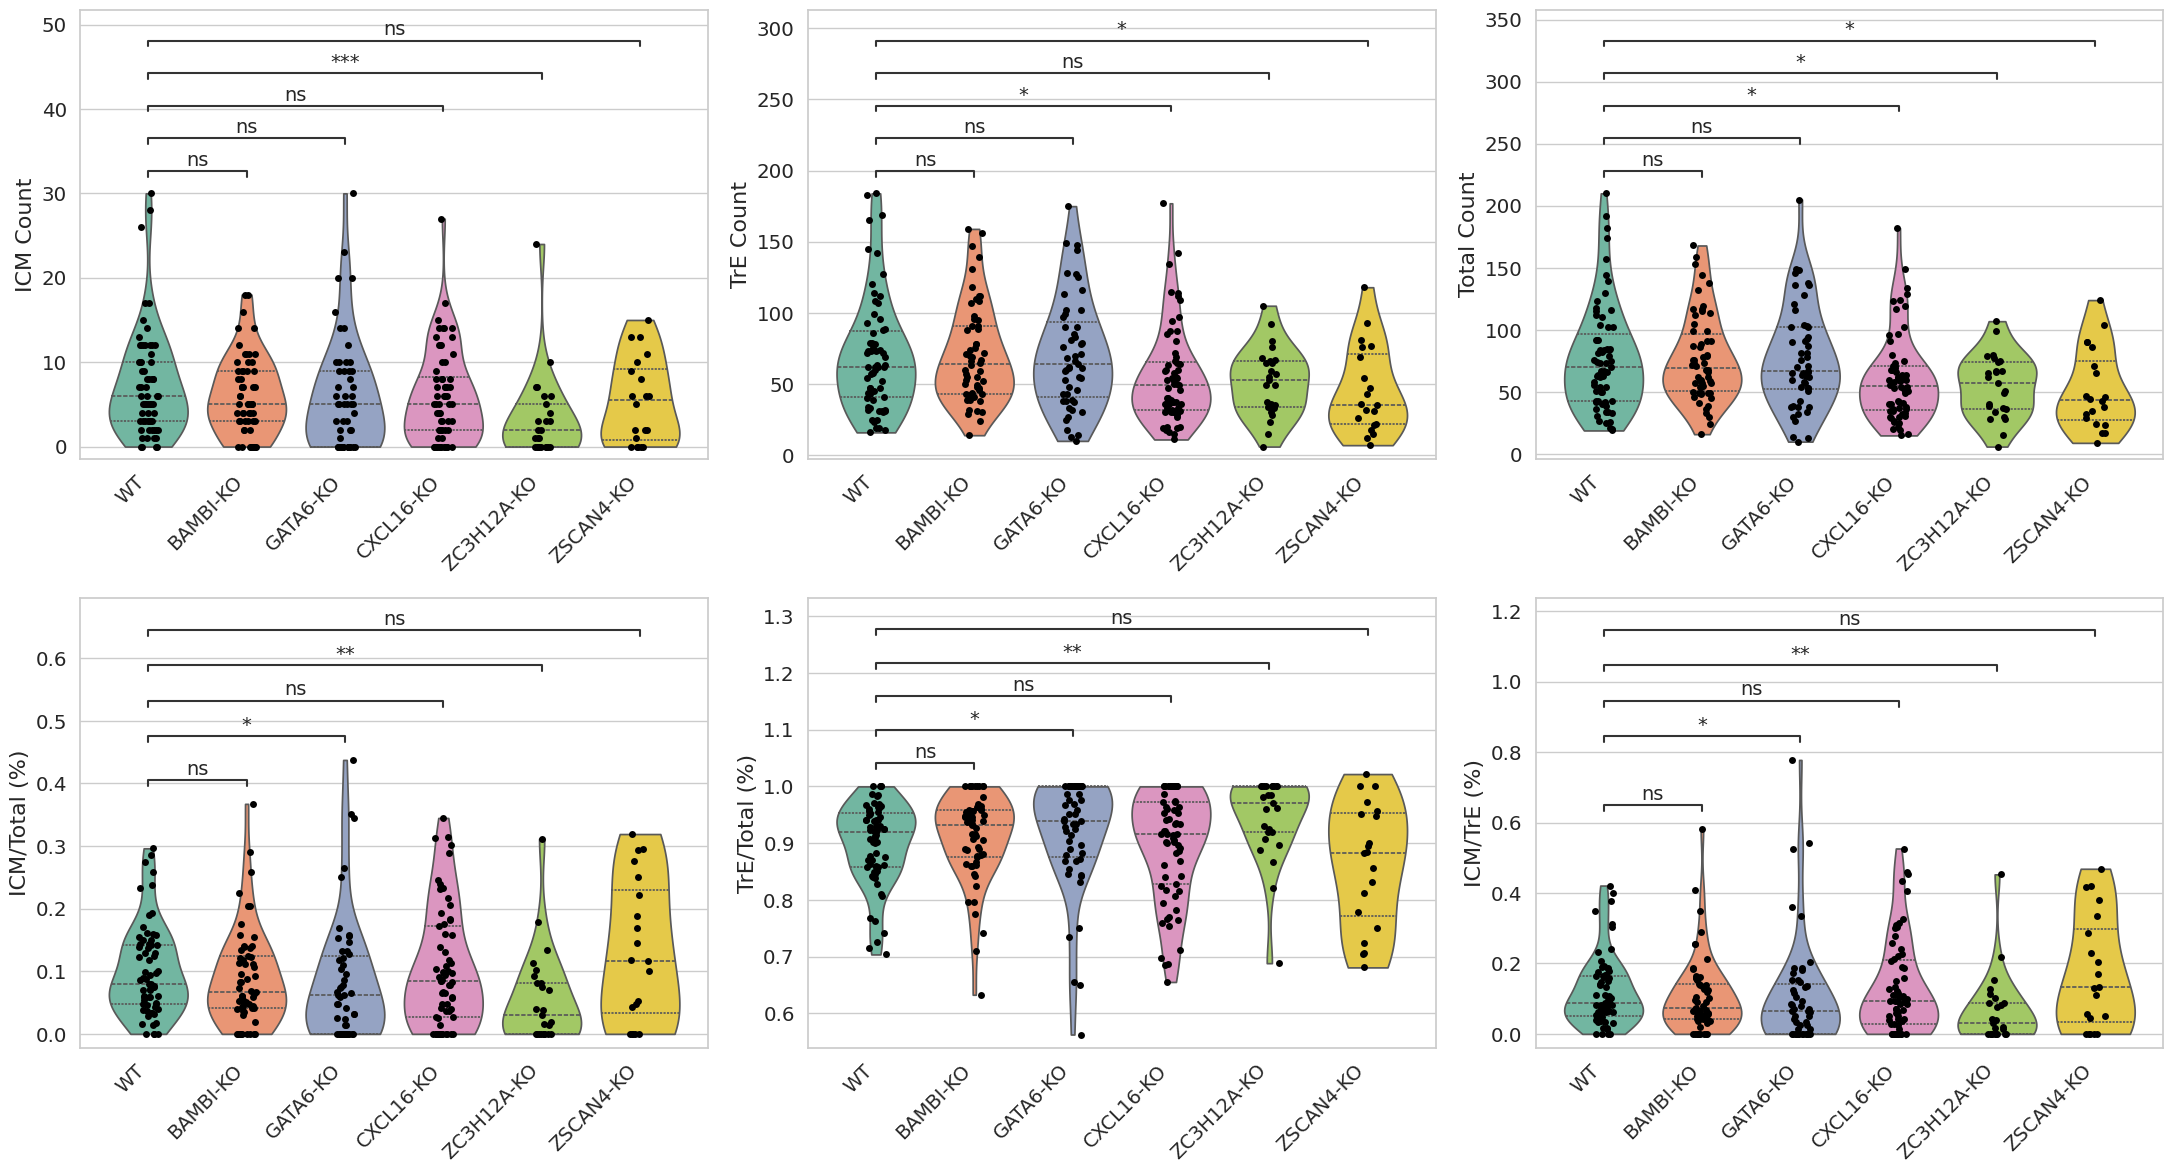

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========= 读取数据 =========
data = pd.read_csv("5个基因敲除统计.txt", sep='\t')

# ========= 参数 =========
y_cols = ['ICM Count', 'TrE Count', 'Total Count', 'ICM/Total (%)', 'TrE/Total (%)', 'ICM/TrE (%)']

# 合并所有rep，只按treatment分组
data_all = data.copy()
data_all['reps'] = 'all'

# ========= 绘图 =========
sns.set(style="whitegrid", font_scale=1.3)
fig, axes = plt.subplots(2, 3, figsize=(22, 12))  # 3列×2行
axes = axes.flatten()

for i, y_col in enumerate(y_cols):
    ax = axes[i]

    sns.violinplot(
        x="treatment",
        y=y_col,
        data=data_all,
        palette="Set2",
        inner="quart",
        cut=0,
        scale="width",
        ax=ax
    )

    sns.stripplot(
        x="treatment",
        y=y_col,
        data=data_all,
        color="black",
        size=5,
        ax=ax
    )

    # 显著性检验
    treatments = data_all['treatment'].unique()
    pairs = [("WT", t) for t in treatments if t != "WT"]

    if len(treatments) > 1:
        annotator = Annotator(ax, pairs, data=data_all, x="treatment", y=y_col)
        annotator.configure(
            test='Mann-Whitney',
            text_format='star',
            loc='inside',
            fontsize=14
        )
        annotator.apply_and_annotate()

    #ax.set_title(y_col, fontsize=20)
    ax.set_xlabel("")
    ax.set_ylabel(y_col, fontsize=16)
    ax.tick_params(axis='x', labelsize=14)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# 去除多余空白子图（如果y_cols < 总子图数）
for j in range(len(y_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig("ICM_TrE_violin_all_6metrics.svg", dpi=300, bbox_inches='tight', transparent=True)
plt.show()


/home/lihaoxing/tmp/ipykernel_995387/3051798872.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_995387/3051798872.py:39: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:5.090e-01 U_stat=2.076e+03
WT vs. GATA6-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.187e-01 U_stat=1.995e+03
WT vs. CXCL16-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.623e-01 U_stat=2.447e+03
WT vs. ZC3H12A-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.784e-04 U_stat=1.250e+03


/home/lihaoxing/tmp/ipykernel_995387/3051798872.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_995387/3051798872.py:39: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:7.122e-01 U_stat=1.868e+03
WT vs. GATA6-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:7.568e-01 U_stat=1.651e+03
WT vs. CXCL16-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.861e-02 U_stat=2.656e+03
WT vs. ZC3H12A-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:7.403e-02 U_stat=1.042e+03


/home/lihaoxing/tmp/ipykernel_995387/3051798872.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_995387/3051798872.py:39: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:7.589e-01 U_stat=1.880e+03
WT vs. GATA6-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:8.662e-01 U_stat=1.677e+03
WT vs. CXCL16-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.623e-02 U_stat=2.666e+03
WT vs. ZC3H12A-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.665e-02 U_stat=1.090e+03


... (2 outputs left out)

/home/lihaoxing/tmp/ipykernel_995387/3051798872.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_995387/3051798872.py:39: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.374e-01 U_stat=1.704e+03
WT vs. GATA6-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.844e-02 U_stat=1.306e+03
WT vs. CXCL16-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:7.574e-01 U_stat=2.076e+03
WT vs. ZC3H12A-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.918e-03 U_stat=4.840e+02


/home/lihaoxing/tmp/ipykernel_995387/3051798872.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_995387/3051798872.py:39: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. BAMBI-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.374e-01 U_stat=2.182e+03
WT vs. GATA6-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:2.844e-02 U_stat=2.112e+03
WT vs. CXCL16-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:7.574e-01 U_stat=2.212e+03
WT vs. ZC3H12A-KO: Mann-Whitney-Wilcoxon test two-sided, P_val:1.918e-03 U_stat=1.191e+03


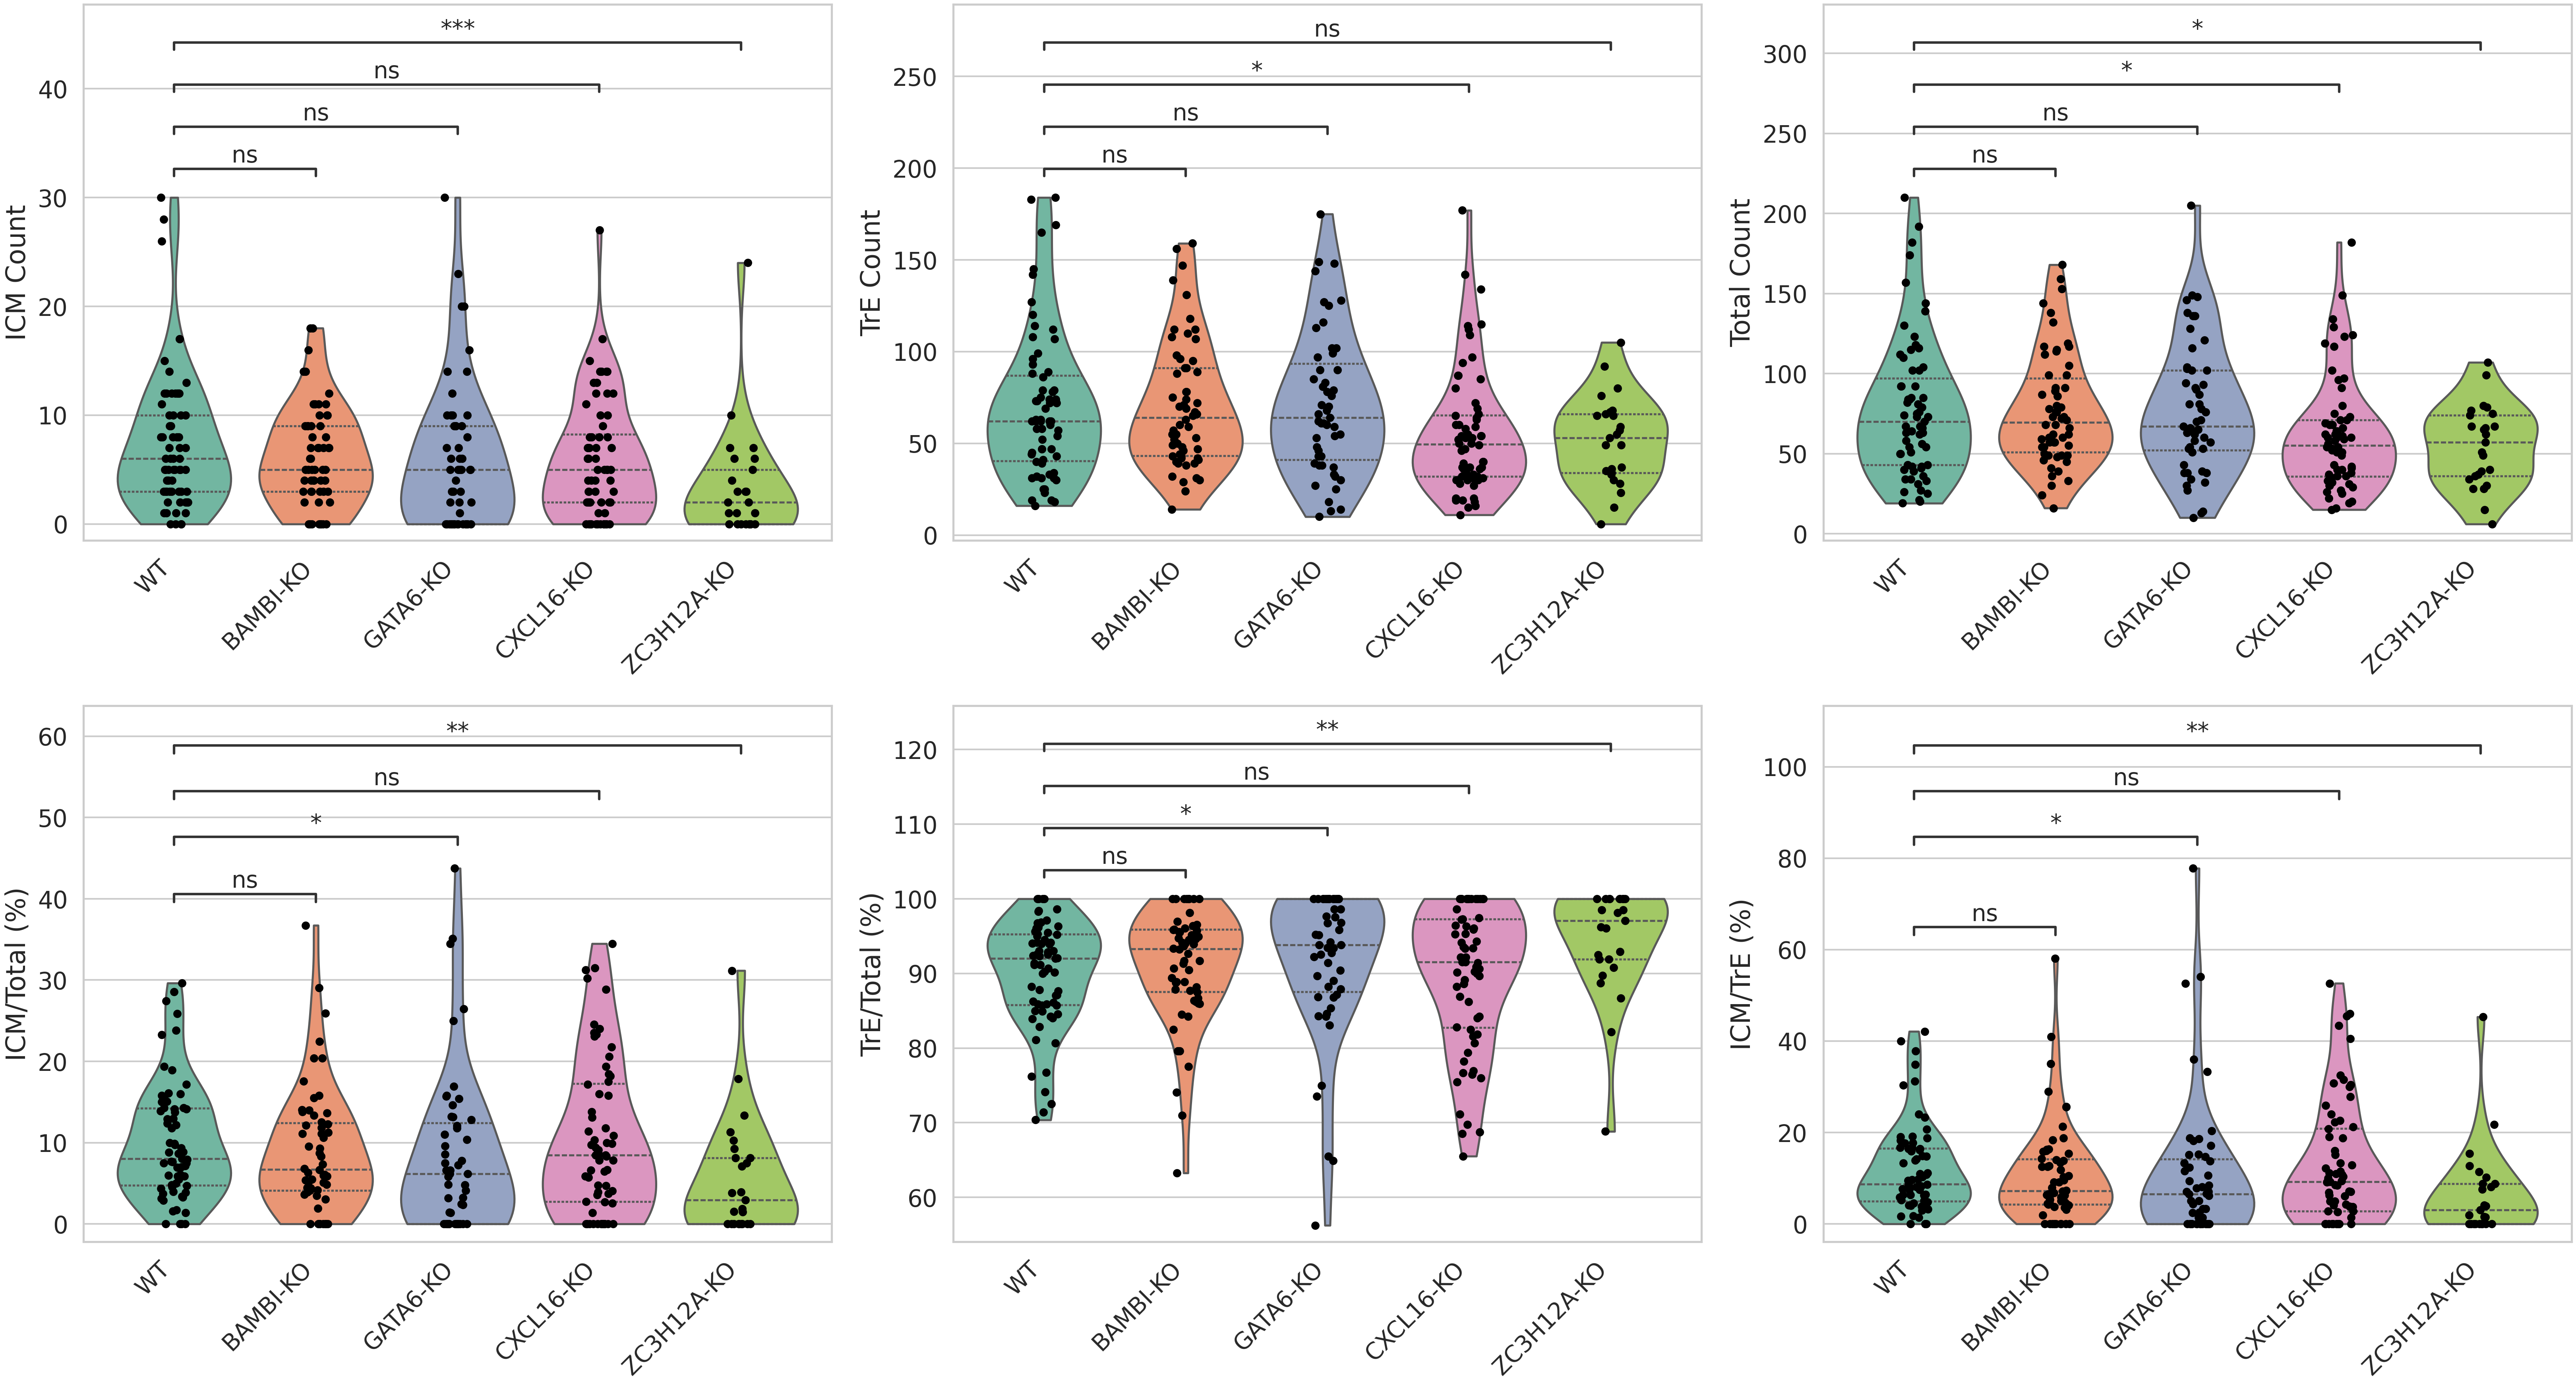

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========= 读取数据 =========
data = pd.read_csv("5个基因敲除统计.txt", sep='\t')

# ========= 排除 ZSCAN4-KO =========
data = data[data['treatment'] != 'ZSCAN4-KO'].copy()

# ========= 百分比列乘以 100 =========
pct_cols = ['ICM/Total (%)', 'TrE/Total (%)', 'ICM/TrE (%)']
data[pct_cols] = data[pct_cols] * 100

# ========= 参数 =========
y_cols = ['ICM Count', 'TrE Count', 'Total Count', 'ICM/Total (%)', 'TrE/Total (%)', 'ICM/TrE (%)']

# 合并所有rep，只按treatment分组
data_all = data.copy()
data_all['reps'] = 'all'

# ========= 绘图 =========
sns.set(style="whitegrid", font_scale=1.3)
fig, axes = plt.subplots(2, 3, figsize=(22, 12))  # 3列×2行
axes = axes.flatten()

for i, y_col in enumerate(y_cols):
    ax = axes[i]

    treatments = list(data_all['treatment'].unique())
    pairs = [("WT", t) for t in treatments if t != "WT"]

    sns.violinplot(
        x="treatment",
        y=y_col,
        data=data_all,
        palette="Set2",
        inner="quart",
        cut=0,
        scale="width",
        order=treatments,
        ax=ax
    )

    sns.stripplot(
        x="treatment",
        y=y_col,
        data=data_all,
        color="black",
        size=5,
        order=treatments,
        ax=ax
    )

    # 显著性检验
    if len(treatments) > 1:
        annotator = Annotator(
            ax,
            pairs,
            data=data_all,
            x="treatment",
            y=y_col,
            order=treatments
        )
        annotator.configure(
            test='Mann-Whitney',
            text_format='star',
            loc='inside',
            fontsize=14
        )
        annotator.apply_and_annotate()

    # x轴标签：直接使用原始字符串（不斜体、不拆分字符）
    ax.set_xticks(range(len(treatments)))
    ax.set_xticklabels(treatments)

    # ax.set_title(y_col, fontsize=20)
    ax.set_xlabel("")
    ax.set_ylabel(y_col, fontsize=16)
    ax.tick_params(axis='x', labelsize=14)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# 去除多余空白子图
for j in range(len(y_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(
    "ICM_TrE_violin_all_6metrics.svg",
    dpi=300,
    bbox_inches='tight',
    transparent=True
)
plt.show()

In [11]:
# ============================================================
# 过滤前：所有囊胚都用于统计
# （已去除 ZSCAN4-KO，因其实验设计与其它基因不同）
# ============================================================

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt


plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'


# ============================================================
# 1. 读取数据
# ============================================================

df_cleavage = pd.read_csv(
    "5次重复卵裂率统计.txt",
    sep="\t"
)

df_blastocyst = pd.read_csv(
    "5次重复囊胚率统计.txt",
    sep="\t"
)

df_icm = pd.read_csv(
    "5个基因敲除统计.txt",
    sep="\t"
)


# ============================================================
# 1.1 去除 ZSCAN4-KO（实验设计与其它基因不同）
# ============================================================

# 长表：直接按 treatment 过滤
df_cleavage = df_cleavage[
    df_cleavage["treatment"] != "ZSCAN4-KO"
].copy()

df_icm = df_icm[
    df_icm["treatment"] != "ZSCAN4-KO"
].copy()

# 宽表：若存在该列则删除
if "ZSCAN4-KO" in df_blastocyst.columns:
    df_blastocyst = df_blastocyst.drop(
        columns=["ZSCAN4-KO"]
    )


# ============================================================
# 2. 分组顺序（已移除 ZSCAN4-KO）
# ============================================================

order = [
    "WT",
    "BAMBI-KO",
    "CXCL16-KO",
    "GATA6-KO",
    "ZC3H12A-KO"
]


# ============================================================
# 3. 卵裂率
# ============================================================

df_cleavage["cleavage_rate"] = (
    df_cleavage["cleavage_rate"] * 100
)

cleavage_stats = (
    df_cleavage
    .groupby("treatment")["cleavage_rate"]
    .agg(["mean", "std"])
    .reset_index()
)

cleavage_stats["metric"] = "Cleavage rate (%)"


# ============================================================
# 4. 囊胚率
# ============================================================

df_blastocyst_melt = df_blastocyst.melt(
    var_name="treatment",
    value_name="blastocyst_rate"
)

df_blastocyst_melt["blastocyst_rate"] = (
    df_blastocyst_melt["blastocyst_rate"] * 100
)

blastocyst_stats = (
    df_blastocyst_melt
    .groupby("treatment")["blastocyst_rate"]
    .agg(["mean", "std"])
    .reset_index()
)

blastocyst_stats["metric"] = "Blastocyst rate (%)"


# ============================================================
# 5. ICM / TrE
# ============================================================

icm_metrics = [
    "ICM Count",
    "TrE Count",
    "Total Count",
    "ICM/Total (%)",
    "TrE/Total (%)",
    "ICM/TrE (%)"
]

df_icm_melt = df_icm.melt(
    id_vars=["treatment", "reps"],
    value_vars=icm_metrics,
    var_name="metric",
    value_name="value"
)

icm_stats = (
    df_icm_melt
    .groupby(["treatment", "metric"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)

icm_stats.columns = [
    "treatment",
    "metric",
    "mean",
    "std"
]


# ============================================================
# 6. 合并统计量
# ============================================================

stats_all = pd.concat(
    [
        cleavage_stats,
        blastocyst_stats,
        icm_stats
    ],
    ignore_index=True
)

stats_all = stats_all[
    stats_all["treatment"].isin(order)
]


# ============================================================
# 7. 平均值和 SD
# ============================================================

pivot_mean = stats_all.pivot(
    index="metric",
    columns="treatment",
    values="mean"
)

pivot_std = stats_all.pivot(
    index="metric",
    columns="treatment",
    values="std"
)

# 确保列顺序与 order 一致
pivot_mean = pivot_mean.reindex(columns=order)
pivot_std = pivot_std.reindex(columns=order)


# ============================================================
# 8. 格式化 mean ± SD
#    n = 1 时 SD 为 NA
# ============================================================

def format_mean_sd(mean, sd):

    if pd.isna(mean):
        return "NA"

    if pd.isna(sd):
        return f"{mean:.2f} ± NA"

    return f"{mean:.2f} ± {sd:.2f}"


table_mean_std = pivot_mean.copy().astype(object)

for metric in pivot_mean.index:
    for treatment in pivot_mean.columns:

        mean = pivot_mean.loc[metric, treatment]
        sd = pivot_std.loc[metric, treatment]

        table_mean_std.loc[
            metric,
            treatment
        ] = format_mean_sd(mean, sd)


# ============================================================
# 9. 显著性检验
# ============================================================

# ------------------------------------------------------------
# 9.1 卵裂率：配对 t 检验
#
# 只有当 WT 和 KO 都有相同数量的有效重复时才进行。
# ------------------------------------------------------------

wt_cleavage_df = (
    df_cleavage[
        df_cleavage["treatment"] == "WT"
    ]
    .sort_values("reps")
)

wt_cleavage = (
    wt_cleavage_df["cleavage_rate"]
    .dropna()
    .values
)

cleavage_pvals = {}

for g in order:

    if g == "WT":
        continue

    g_df = (
        df_cleavage[
            df_cleavage["treatment"] == g
        ]
        .sort_values("reps")
    )

    g_vals = (
        g_df["cleavage_rate"]
        .dropna()
        .values
    )

    # 配对 t 检验要求长度一致且至少有 2 对
    if (
        len(wt_cleavage) == len(g_vals)
        and len(g_vals) >= 2
    ):

        _, p = stats.ttest_rel(
            wt_cleavage,
            g_vals
        )

        cleavage_pvals[g] = p

    else:

        cleavage_pvals[g] = np.nan

        print(
            f"[跳过卵裂率检验] {g}: "
            f"WT n={len(wt_cleavage)}, "
            f"{g} n={len(g_vals)}"
        )


# ------------------------------------------------------------
# 9.2 囊胚率：配对 t 检验
# ------------------------------------------------------------

wt_blastocyst = (
    df_blastocyst["WT"]
    .dropna()
    .values * 100
)

blastocyst_pvals = {}

for g in order:

    if g == "WT":
        continue

    if g not in df_blastocyst.columns:

        blastocyst_pvals[g] = np.nan

        print(
            f"[跳过囊胚率检验] {g}: "
            f"数据列不存在"
        )

        continue

    g_vals = (
        df_blastocyst[g]
        .dropna()
        .values * 100
    )

    # 配对 t 检验要求长度一致且至少有 2 对
    if (
        len(wt_blastocyst) == len(g_vals)
        and len(g_vals) >= 2
    ):

        _, p = stats.ttest_rel(
            wt_blastocyst,
            g_vals
        )

        blastocyst_pvals[g] = p

    else:

        blastocyst_pvals[g] = np.nan

        print(
            f"[跳过囊胚率检验] {g}: "
            f"WT n={len(wt_blastocyst)}, "
            f"{g} n={len(g_vals)}"
        )


# ------------------------------------------------------------
# 9.3 ICM / TrE：Mann–Whitney U
# ------------------------------------------------------------

icm_pvals = {}

for metric in icm_metrics:

    wt_vals = (
        df_icm[
            df_icm["treatment"] == "WT"
        ][metric]
        .dropna()
        .values
    )

    for g in order:

        if g == "WT":
            continue

        g_vals = (
            df_icm[
                df_icm["treatment"] == g
            ][metric]
            .dropna()
            .values
        )

        if len(wt_vals) == 0 or len(g_vals) == 0:

            icm_pvals[
                (metric, g)
            ] = np.nan

            continue

        _, p = stats.mannwhitneyu(
            wt_vals,
            g_vals,
            alternative="two-sided"
        )

        icm_pvals[
            (metric, g)
        ] = p


# ============================================================
# 10. 构建 p 值表
# ============================================================

metric_order = [
    "Cleavage rate (%)",
    "Blastocyst rate (%)"
] + icm_metrics

pivot_p = pd.DataFrame(
    index=metric_order,
    columns=order,
    dtype=float
)

for metric in pivot_p.index:

    for g in order:

        if g == "WT":

            pivot_p.loc[
                metric,
                g
            ] = np.nan

        elif metric == "Cleavage rate (%)":

            pivot_p.loc[
                metric,
                g
            ] = cleavage_pvals.get(
                g,
                np.nan
            )

        elif metric == "Blastocyst rate (%)":

            pivot_p.loc[
                metric,
                g
            ] = blastocyst_pvals.get(
                g,
                np.nan
            )

        else:

            pivot_p.loc[
                metric,
                g
            ] = icm_pvals.get(
                (metric, g),
                np.nan
            )


# ============================================================
# 11. 趋势方向
# ============================================================

trend = pd.DataFrame(
    index=metric_order,
    columns=order
)

for metric in trend.index:

    wt_mean = pivot_mean.loc[
        metric,
        "WT"
    ]

    for g in order:

        if g == "WT":

            trend.loc[
                metric,
                g
            ] = ""

        else:

            ko_mean = pivot_mean.loc[
                metric,
                g
            ]

            if pd.isna(ko_mean) or pd.isna(wt_mean):

                trend.loc[
                    metric,
                    g
                ] = ""

            elif ko_mean > wt_mean:

                trend.loc[
                    metric,
                    g
                ] = "↑"

            elif ko_mean < wt_mean:

                trend.loc[
                    metric,
                    g
                ] = "↓"

            else:

                trend.loc[
                    metric,
                    g
                ] = "→"


# ============================================================
# 12. 构建最终表格
# ============================================================

final_df = pd.DataFrame(
    index=metric_order,
    columns=order
)

for metric in final_df.index:

    for g in order:

        mean_std = table_mean_std.loc[
            metric,
            g
        ]

        if g == "WT":

            final_df.loc[
                metric,
                g
            ] = mean_std

        else:

            p_val = pivot_p.loc[
                metric,
                g
            ]

            if pd.isna(p_val):

                final_df.loc[
                    metric,
                    g
                ] = mean_std

            elif p_val < 0.05:

                trend_str = trend.loc[
                    metric,
                    g
                ]

                final_df.loc[
                    metric,
                    g
                ] = (
                    f"{mean_std} "
                    f"*{trend_str}"
                )

            else:

                final_df.loc[
                    metric,
                    g
                ] = mean_std


# ============================================================
# 13. 打印最终表格
# ============================================================

print("\n========================================")
print("Final summary table")
print("========================================")

print(final_df.to_string())


# ============================================================
# 14. 绘制 SVG 表格
# ============================================================

def draw_table_to_svg(
    df,
    order,
    filename="summary_table.svg"
):

    fig, ax = plt.subplots(
        figsize=(
            12,
            0.6 * (len(df.index) + 1)
        )
    )

    ax.axis("off")
    ax.axis("tight")


    # --------------------------------------------------------
    # Table contents
    # --------------------------------------------------------

    cell_text = []
    cell_colours = []

    row_labels = df.index.tolist()
    col_labels = order


    for metric in df.index:

        row = []
        colors = []

        for g in order:

            cell = df.loc[
                metric,
                g
            ]

            row.append(cell)

            # 显著 KO 单元格黄色
            if (
                g != "WT"
                and isinstance(cell, str)
                and "*" in cell
            ):

                colors.append("yellow")

            else:

                colors.append("white")

        cell_text.append(row)
        cell_colours.append(colors)


    # --------------------------------------------------------
    # Header
    # --------------------------------------------------------

    cell_text.insert(
        0,
        col_labels
    )

    cell_colours.insert(
        0,
        ["lightgray"] * len(col_labels)
    )


    row_labels_with_header = (
        [""]
        + row_labels
    )


    # --------------------------------------------------------
    # Table
    # --------------------------------------------------------

    table = ax.table(
        cellText=cell_text,
        rowLabels=row_labels_with_header,
        cellColours=cell_colours,
        loc="center",
        cellLoc="center",
        colWidths=[
            0.2
        ] + [
            0.14
        ] * len(order)
    )


    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.5)


    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    for (row, col), cell in table.get_celld().items():

        # Row labels
        if col == -1:

            cell.set_text_props(
                weight="bold"
            )

        # Header
        if row == 0:

            cell.set_text_props(
                weight="bold"
            )

            cell.set_facecolor(
                "lightgray"
            )


    plt.tight_layout()

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        transparent=True
    )

    plt.close()

    print(
        f"\n表格已保存为: {filename}"
    )


# ============================================================
# 15. 执行
# ============================================================

draw_table_to_svg(
    final_df,
    order,
    "summary_table.svg"
)


Final summary table
                                WT         BAMBI-KO         CXCL16-KO         GATA6-KO        ZC3H12A-KO
Cleavage rate (%)     97.95 ± 1.67     97.11 ± 1.67      97.29 ± 0.90     96.88 ± 1.47      98.45 ± 1.60
Blastocyst rate (%)  45.48 ± 12.52  32.10 ± 7.88 *↓   32.49 ± 4.57 *↓  25.76 ± 3.73 *↓      40.81 ± 6.89
ICM Count              7.31 ± 6.27      6.19 ± 4.61       5.89 ± 5.46      6.18 ± 6.75    3.40 ± 5.15 *↓
TrE Count            69.93 ± 40.38    70.64 ± 34.45  55.23 ± 33.60 *↓    71.08 ± 39.08     51.32 ± 23.91
Total Count          77.24 ± 43.20    76.83 ± 34.98  61.12 ± 35.05 *↓    77.25 ± 41.16  54.72 ± 25.32 *↓
ICM/Total (%)          0.10 ± 0.07      0.09 ± 0.08       0.11 ± 0.10   0.08 ± 0.10 *↓    0.06 ± 0.07 *↓
TrE/Total (%)          0.90 ± 0.07      0.91 ± 0.08       0.89 ± 0.10   0.92 ± 0.10 *↑    0.94 ± 0.07 *↑
ICM/TrE (%)            0.12 ± 0.10      0.11 ± 0.11       0.13 ± 0.13   0.11 ± 0.16 *↓    0.07 ± 0.10 *↓

表格已保存为: summary_table.svg


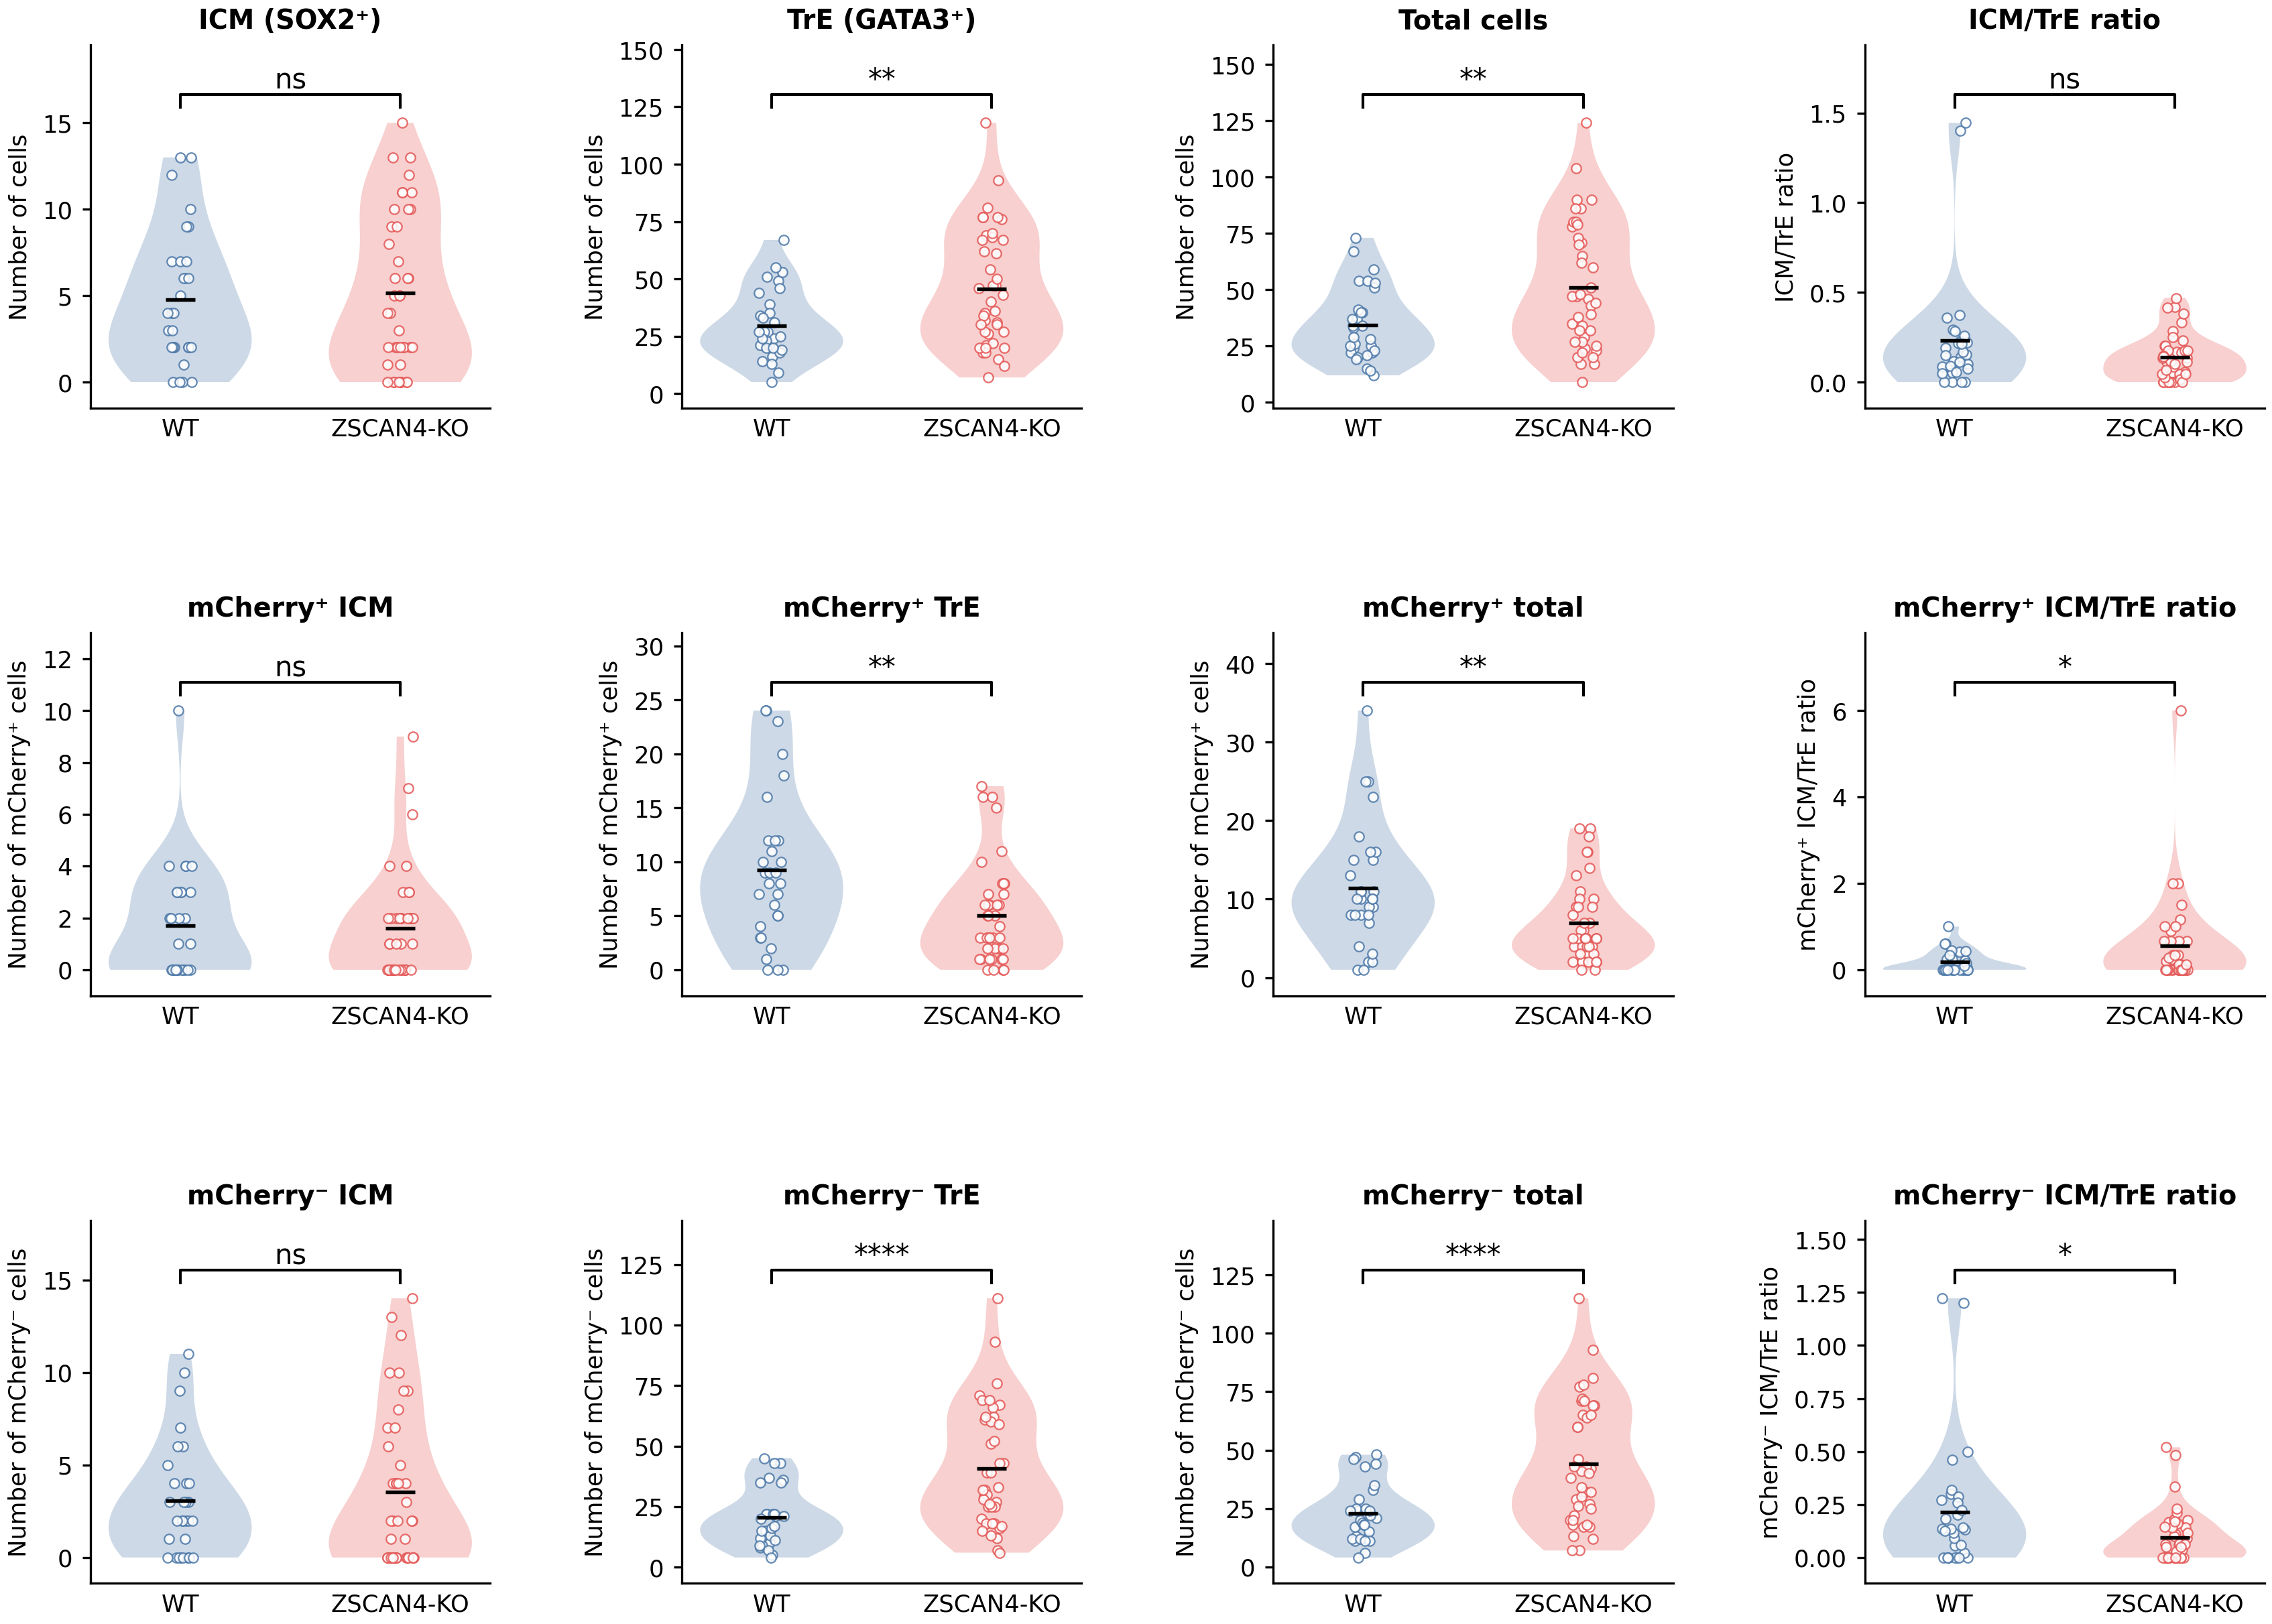


WT vs ZSCAN4-KO — Welch's t-test
Metric                     WT mean±SD (n)         KO mean±SD (n)               t      df          P  
------------------------------------------------------------------------------------------
[All cells]
  ICM (SOX2⁺)              4.77±3.88 (30)         5.15±4.52 (41)           -0.38   67.15     0.7055  ns
  TrE (GATA3⁺)             29.67±14.99 (30)       45.63±25.66 (41)         -3.29   66.16   0.001603  **
  Total cells              34.40±16.03 (30)       51.07±27.79 (41)         -3.19   65.86   0.002211  **
  ICM/TrE ratio            0.23±0.34 (30)         0.14±0.13 (41)            1.44   35.03     0.1593  ns

[mCherry+ cells]
  mCherry⁺ ICM             1.70±2.20 (30)         1.61±2.05 (41)            0.18   59.97     0.8611  ns
  mCherry⁺ TrE             9.27±7.03 (30)         5.02±4.62 (41)            2.88   46.83   0.005938  **
  mCherry⁺ total           11.43±7.73 (30)        6.95±5.12 (41)            2.76   47.07   0.008144  **
  mCherry⁺ ICM/

In [6]:
"""
WT vs ZSCAN4-KO — light publication style
-----------------------------------------
Compares three cell populations between WT and ZSCAN4-KO embryos:

    1. All cells        (SOX2, GATA3, total, ratio)
    2. mCherry+ cells   (mCherry-ICM, mCherry-TE, mCherry-total, ratio)
    3. mCherry- cells   (SOX2 - mCherry-ICM, GATA3 - mCherry-TE,
                         total - mCherry-total, ratio)

Statistical test:
    - Welch's t-test by default (does NOT assume equal variances).
    - Set EQUAL_VAR = True to use Student's t-test instead.

Plot style:
    - Violin (background) + hollow scatter (individual embryos)
    - Black mean tick
    - Significance bracket with stars

Outputs:
    - WT_vs_ZSCAN4-KO_cells_summary_ttest.svg
    - Statistics printed to stdout.
"""

from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind

# ============================================================
# Configuration
# ============================================================

INPUT_FILE = Path("red_icm_te_count.txt")
OUTPUT_FILE = Path("WT_vs_ZSCAN4-KO_cells_summary_ttest.svg")

GROUP_COL = "treatment"
GROUPS = ("WT", "ZSCAN4-KO")
SHORT_LABELS = ("WT", "ZSCAN4-KO")

NUMERIC_COLUMNS = (
    "mCherry-ICM", "mCherry-TE", "mCherry-total",
    "SOX2", "GATA3", "total",
)

RNG_SEED = 123

# Welch's t-test (False) vs Student's t-test (True)
EQUAL_VAR = False

# ------------------------------------------------------------
# Palette (same as the ZSCAN4 heterogeneity figure)
# ------------------------------------------------------------

COLOR_WT = "#4C78A8"
COLOR_KO = "#E45756"
COLORS = (COLOR_WT, COLOR_KO)

# ============================================================
# Metrics
# ============================================================

@dataclass(frozen=True)
class Metric:
    """A single panel: display label, source column, and y-axis label."""
    label: str
    column: str
    ylabel: str


# --- Row 1: all cells ------------------------------------------------------
ALLCELL_METRICS = (
    Metric("ICM (SOX2\u207A)",  "SOX2",              "Number of cells"),
    Metric("TrE (GATA3\u207A)", "GATA3",             "Number of cells"),
    Metric("Total cells",       "total",             "Number of cells"),
    Metric("ICM/TrE ratio",     "all_ICM_TrE_ratio", "ICM/TrE ratio"),
)

# --- Row 2: mCherry+ cells -------------------------------------------------
MCHERRY_POS_METRICS = (
    Metric("mCherry\u207A ICM",           "mCherry-ICM",           "Number of mCherry\u207A cells"),
    Metric("mCherry\u207A TrE",           "mCherry-TE",            "Number of mCherry\u207A cells"),
    Metric("mCherry\u207A total",         "mCherry-total",         "Number of mCherry\u207A cells"),
    Metric("mCherry\u207A ICM/TrE ratio", "mCherry_ICM_TrE_ratio", "mCherry\u207A ICM/TrE ratio"),
)

# --- Row 3: mCherry- cells -------------------------------------------------
MCHERRY_NEG_METRICS = (
    Metric("mCherry\u207B ICM",           "mCherry_neg_ICM",           "Number of mCherry\u207B cells"),
    Metric("mCherry\u207B TrE",           "mCherry_neg_TrE",           "Number of mCherry\u207B cells"),
    Metric("mCherry\u207B total",         "mCherry_neg_total",         "Number of mCherry\u207B cells"),
    Metric("mCherry\u207B ICM/TrE ratio", "mCherry_neg_ICM_TrE_ratio", "mCherry\u207B ICM/TrE ratio"),
)

METRIC_ROWS: tuple[tuple[str, tuple[Metric, ...]], ...] = (
    ("All cells",      ALLCELL_METRICS),
    ("mCherry+ cells", MCHERRY_POS_METRICS),
    ("mCherry- cells", MCHERRY_NEG_METRICS),
)


def all_metrics() -> tuple[Metric, ...]:
    return tuple(m for _, row in METRIC_ROWS for m in row)


# ============================================================
# Matplotlib style
# ============================================================

def configure_matplotlib() -> None:
    plt.rcParams.update({
        "font.family":     "DejaVu Sans",
        "font.size":       9,
        "axes.titlesize":  9.5,
        "axes.labelsize":  8.5,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,

        "svg.fonttype":    "none",
        "svg.hashsalt":    "hello",
        "pdf.fonttype":    42,

        "axes.linewidth":    0.8,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "xtick.major.size":  3,
        "ytick.major.size":  3,

        "figure.dpi":        300,
        "savefig.dpi":       600,
        "savefig.bbox":      "tight",
        "savefig.pad_inches": 0.04,

        "mathtext.fontset":  "dejavusans",
    })


# ============================================================
# Data loading and preprocessing
# ============================================================

def add_derived_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Add ratio and mCherry-negative columns used by the panels."""
    df = df.copy()

    df["mCherry_ICM_TrE_ratio"] = (
        df["mCherry-ICM"] / df["mCherry-TE"].replace(0, np.nan)
    )
    df["all_ICM_TrE_ratio"] = (
        df["SOX2"] / df["GATA3"].replace(0, np.nan)
    )

    df["mCherry_neg_ICM"]   = df["SOX2"]  - df["mCherry-ICM"]
    df["mCherry_neg_TrE"]   = df["GATA3"] - df["mCherry-TE"]
    df["mCherry_neg_total"] = df["total"] - df["mCherry-total"]

    df["mCherry_neg_ICM_TrE_ratio"] = (
        df["mCherry_neg_ICM"] / df["mCherry_neg_TrE"].replace(0, np.nan)
    )
    return df


def _check_nonneg(df: pd.DataFrame) -> None:
    """Warn if any derived mCherry- count is negative."""
    for col in ("mCherry_neg_ICM", "mCherry_neg_TrE", "mCherry_neg_total"):
        bad = df[df[col] < 0]
        if not bad.empty:
            print(f"WARNING: {col} < 0 for {len(bad)} embryo(s):")
            id_col = "编号" if "编号" in df.columns else df.index.name or "index"
            print(bad[[id_col, GROUP_COL, col]].to_string(index=False))


def load_data(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, sep="\t")
    df = df[df[GROUP_COL].isin(GROUPS)].copy()

    for col in NUMERIC_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = add_derived_columns(df)
    _check_nonneg(df)
    return df


def values_for(df: pd.DataFrame, column: str, group: str) -> np.ndarray:
    """Return the non-NaN values of ``column`` for a given group."""
    return df.loc[df[GROUP_COL] == group, column].dropna().to_numpy()


# ============================================================
# Statistics (t-test)
# ============================================================

def p_to_star(p: float) -> str:
    if p < 1e-4:
        return "****"
    if p < 1e-3:
        return "***"
    if p < 1e-2:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"


@dataclass(frozen=True)
class TestResult:
    t: float
    p: float
    df: float
    mean_wt: float
    mean_ko: float
    sd_wt: float
    sd_ko: float
    n_wt: int
    n_ko: int

    @property
    def stars(self) -> str:
        return p_to_star(self.p)


def _welch_dof(a: np.ndarray, b: np.ndarray) -> float:
    """Welch–Satterthwaite degrees of freedom (only used for display)."""
    va, vb = a.var(ddof=1), b.var(ddof=1)
    na, nb = a.size, b.size
    num = (va / na + vb / nb) ** 2
    den = (va / na) ** 2 / (na - 1) + (vb / nb) ** 2 / (nb - 1)
    return num / den if den > 0 else float(na + nb - 2)


def run_ttest(df: pd.DataFrame) -> dict[str, TestResult]:
    """Two-sided t-test for every metric (Welch by default)."""
    results: dict[str, TestResult] = {}
    for metric in all_metrics():
        wt = values_for(df, metric.column, GROUPS[0])
        ko = values_for(df, metric.column, GROUPS[1])

        if wt.size < 2 or ko.size < 2:
            raise ValueError(
                f"Metric '{metric.label}' needs n>=2 in both groups "
                f"(WT n={wt.size}, {GROUPS[1]} n={ko.size})."
            )

        t, p = ttest_ind(wt, ko, equal_var=EQUAL_VAR, alternative="two-sided")

        dof = (
            (wt.size + ko.size - 2) if EQUAL_VAR
            else _welch_dof(wt, ko)
        )

        results[metric.label] = TestResult(
            t=float(t), p=float(p), df=float(dof),
            mean_wt=float(wt.mean()), mean_ko=float(ko.mean()),
            sd_wt=float(wt.std(ddof=1)), sd_ko=float(ko.std(ddof=1)),
            n_wt=wt.size, n_ko=ko.size,
        )
    return results


# ============================================================
# Plotting helpers
# ============================================================

def style_axes(ax: plt.Axes) -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", length=0)


def add_sig_bracket(
    ax: plt.Axes,
    x1: float,
    x2: float,
    y: float,
    h: float,
    label: str,
    fontsize: int = 10,
) -> None:
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        lw=1.0, color="black", clip_on=False,
    )
    ax.text(
        (x1 + x2) / 2, y + h, label,
        ha="center", va="bottom", fontsize=fontsize, color="black",
    )


def _jitter(rng: np.random.Generator, n: int, center: float, width: float = 0.06) -> np.ndarray:
    return center + rng.uniform(-width, width, n)


def plot_metric(
    ax: plt.Axes,
    metric: Metric,
    wt: np.ndarray,
    ko: np.ndarray,
    p: float,
    rng: np.random.Generator,
) -> None:
    """Draw one violin + hollow scatter + mean tick panel."""
    # --- Violin (background) ---
    violin = ax.violinplot(
        [wt, ko],
        positions=[0, 1],
        widths=0.65,
        showmeans=False,
        showmedians=False,
        showextrema=False,
    )

    for i, body in enumerate(violin["bodies"]):
        body.set_facecolor(COLORS[i])
        body.set_edgecolor("none")
        body.set_alpha(0.28)

    # --- Hollow scatter (individual embryos) ---
    ax.scatter(
        _jitter(rng, wt.size, 0), wt,
        s=12, facecolor="white", edgecolor=COLOR_WT,
        linewidth=0.55, alpha=0.85, zorder=3,
    )
    ax.scatter(
        _jitter(rng, ko.size, 1), ko,
        s=12, facecolor="white", edgecolor=COLOR_KO,
        linewidth=0.55, alpha=0.85, zorder=3,
    )

    # --- Mean marker ---
    ax.scatter(
        [0, 1],
        [float(np.mean(wt)), float(np.mean(ko))],
        marker="_", s=110, color="black", linewidth=1.3, zorder=7,
    )

    # --- Y-range ---
    all_values = np.concatenate([wt, ko])
    ymin = float(np.min(all_values))
    ymax = float(np.max(all_values))
    yrange = (ymax - ymin) or 1.0

    # --- Significance bracket ---
    add_sig_bracket(
        ax, 0, 1,
        y=ymax + yrange * 0.06,
        h=yrange * 0.05,
        label=p_to_star(p),
        fontsize=10,
    )

    # --- Labels / title / limits ---
    ax.set_xticks([0, 1])
    ax.set_xticklabels(SHORT_LABELS, fontsize=8.5, color="black")
    ax.set_ylabel(metric.ylabel, fontsize=8.5, color="black")
    ax.set_title(metric.label, fontsize=9.5, fontweight="bold",
                 color="black", pad=6)
    ax.set_ylim(ymin - yrange * 0.10, ymax + yrange * 0.30)

    style_axes(ax)


# ============================================================
# Reporting
# ============================================================

def _plain(s: str) -> str:
    """No-op now: labels no longer contain mathtext."""
    return s


def print_tests(results: dict[str, TestResult]) -> None:
    method = "Student's t-test" if EQUAL_VAR else "Welch's t-test"
    print("\n" + "=" * 90)
    print(f"{GROUPS[0]} vs {GROUPS[1]} — {method}")
    print("=" * 90)

    header = (
        f"{'Metric':<26} "
        f"{'WT mean±SD (n)':<22} "
        f"{'KO mean±SD (n)':<22} "
        f"{'t':>7} {'df':>7} {'P':>10}  "
    )
    print(header)
    print("-" * 90)

    for row_name, metrics in METRIC_ROWS:
        print(f"[{row_name}]")
        for metric in metrics:
            r = results[metric.label]
            wt_str = f"{r.mean_wt:.2f}±{r.sd_wt:.2f} ({r.n_wt})"
            ko_str = f"{r.mean_ko:.2f}±{r.sd_ko:.2f} ({r.n_ko})"
            print(
                f"  {_plain(metric.label):<24} "
                f"{wt_str:<22} "
                f"{ko_str:<22} "
                f"{r.t:>7.2f} {r.df:>7.2f} {r.p:>10.4g}  {r.stars}"
            )
        print()


# ============================================================
# Main
# ============================================================

def main() -> None:
    configure_matplotlib()

    df = load_data(INPUT_FILE)
    results = run_ttest(df)

    fig, axes = plt.subplots(3, 4, figsize=(11.5, 8.5))
    rng = np.random.default_rng(RNG_SEED)

    for row_idx, (_, metrics) in enumerate(METRIC_ROWS):
        for col_idx, metric in enumerate(metrics):
            ax = axes[row_idx, col_idx]
            wt = values_for(df, metric.column, GROUPS[0])
            ko = values_for(df, metric.column, GROUPS[1])
            plot_metric(ax, metric, wt, ko, results[metric.label].p, rng)

    fig.subplots_adjust(
        left=0.055, right=0.995,
        bottom=0.055, top=0.955,
        wspace=0.48, hspace=0.62,
    )

    fig.savefig(OUTPUT_FILE, dpi=600, transparent=True)
    plt.show()

    print_tests(results)


if __name__ == "__main__":
    main()

In [18]:
# ============================================================
# 主表：实验一（已去除 ZSCAN4-KO）
# 右侧表：实验二 mCherry+（WT vs ZSCAN4-KO），行指标与主表一致
# 两表拼接，右侧表无 P 列，但有 ↑/↓/→ 箭头
# ============================================================

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt


plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'


# ============================================================
# 1. 读取主表数据
# ============================================================

df_cleavage = pd.read_csv("5次重复卵裂率统计.txt", sep="\t")
df_blastocyst = pd.read_csv("5次重复囊胚率统计.txt", sep="\t")
df_icm = pd.read_csv("5个基因敲除统计.txt", sep="\t")


# ============================================================
# 1.1 去除 ZSCAN4-KO（主表不纳入）
# ============================================================

df_cleavage = df_cleavage[df_cleavage["treatment"] != "ZSCAN4-KO"].copy()
df_icm = df_icm[df_icm["treatment"] != "ZSCAN4-KO"].copy()

if "ZSCAN4-KO" in df_blastocyst.columns:
    df_blastocyst = df_blastocyst.drop(columns=["ZSCAN4-KO"])


# ============================================================
# 1.2 ICM/TrE 百分比列 ×100（文件里是小数，单位标注为 %）
# ============================================================

pct_cols = ["ICM/Total (%)", "TrE/Total (%)", "ICM/TrE (%)"]

for c in pct_cols:
    df_icm[c] = pd.to_numeric(df_icm[c], errors="coerce") * 100


# ============================================================
# 2. 主表分组顺序
# ============================================================

order = [
    "WT",
    "BAMBI-KO",
    "CXCL16-KO",
    "GATA6-KO",
    "ZC3H12A-KO"
]


# ============================================================
# 3. 卵裂率
# ============================================================

df_cleavage["cleavage_rate"] = df_cleavage["cleavage_rate"] * 100

cleavage_stats = (
    df_cleavage
    .groupby("treatment")["cleavage_rate"]
    .agg(["mean", "std"])
    .reset_index()
)
cleavage_stats["metric"] = "Cleavage rate (%)"


# ============================================================
# 4. 囊胚率
# ============================================================

df_blastocyst_melt = df_blastocyst.melt(
    var_name="treatment",
    value_name="blastocyst_rate"
)
df_blastocyst_melt["blastocyst_rate"] = df_blastocyst_melt["blastocyst_rate"] * 100

blastocyst_stats = (
    df_blastocyst_melt
    .groupby("treatment")["blastocyst_rate"]
    .agg(["mean", "std"])
    .reset_index()
)
blastocyst_stats["metric"] = "Blastocyst rate (%)"


# ============================================================
# 5. ICM / TrE
# ============================================================

icm_metrics = [
    "ICM Count",
    "TrE Count",
    "Total Count",
    "ICM/Total (%)",
    "TrE/Total (%)",
    "ICM/TrE (%)"
]

df_icm_melt = df_icm.melt(
    id_vars=["treatment", "reps"],
    value_vars=icm_metrics,
    var_name="metric",
    value_name="value"
)

icm_stats = (
    df_icm_melt
    .groupby(["treatment", "metric"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)
icm_stats.columns = ["treatment", "metric", "mean", "std"]


# ============================================================
# 6. 合并统计量
# ============================================================

stats_all = pd.concat(
    [cleavage_stats, blastocyst_stats, icm_stats],
    ignore_index=True
)
stats_all = stats_all[stats_all["treatment"].isin(order)]


# ============================================================
# 7. 平均值和 SD
# ============================================================

pivot_mean = stats_all.pivot(
    index="metric",
    columns="treatment",
    values="mean"
)
pivot_std = stats_all.pivot(
    index="metric",
    columns="treatment",
    values="std"
)

pivot_mean = pivot_mean.reindex(columns=order)
pivot_std = pivot_std.reindex(columns=order)


# ============================================================
# 8. 格式化 mean ± SD
# ============================================================

def format_mean_sd(mean, sd):
    if pd.isna(mean):
        return "NA"
    if pd.isna(sd):
        return f"{mean:.2f} ± NA"
    return f"{mean:.2f} ± {sd:.2f}"


table_mean_std = pivot_mean.copy().astype(object)

for metric in pivot_mean.index:
    for treatment in pivot_mean.columns:
        mean = pivot_mean.loc[metric, treatment]
        sd = pivot_std.loc[metric, treatment]
        table_mean_std.loc[metric, treatment] = format_mean_sd(mean, sd)


# ============================================================
# 9. 显著性检验（主表）
# ============================================================

# 9.1 卵裂率：配对 t 检验
wt_cleavage_df = (
    df_cleavage[df_cleavage["treatment"] == "WT"]
    .sort_values("reps")
)
wt_cleavage = wt_cleavage_df["cleavage_rate"].dropna().values

cleavage_pvals = {}

for g in order:
    if g == "WT":
        continue

    g_df = (
        df_cleavage[df_cleavage["treatment"] == g]
        .sort_values("reps")
    )
    g_vals = g_df["cleavage_rate"].dropna().values

    if len(wt_cleavage) == len(g_vals) and len(g_vals) >= 2:
        _, p = stats.ttest_rel(wt_cleavage, g_vals)
        cleavage_pvals[g] = p
    else:
        cleavage_pvals[g] = np.nan
        print(
            f"[跳过卵裂率检验] {g}: "
            f"WT n={len(wt_cleavage)}, {g} n={len(g_vals)}"
        )


# 9.2 囊胚率：配对 t 检验
wt_blastocyst = df_blastocyst["WT"].dropna().values * 100

blastocyst_pvals = {}

for g in order:
    if g == "WT":
        continue

    if g not in df_blastocyst.columns:
        blastocyst_pvals[g] = np.nan
        print(f"[跳过囊胚率检验] {g}: 数据列不存在")
        continue

    g_vals = df_blastocyst[g].dropna().values * 100

    if len(wt_blastocyst) == len(g_vals) and len(g_vals) >= 2:
        _, p = stats.ttest_rel(wt_blastocyst, g_vals)
        blastocyst_pvals[g] = p
    else:
        blastocyst_pvals[g] = np.nan
        print(
            f"[跳过囊胚率检验] {g}: "
            f"WT n={len(wt_blastocyst)}, {g} n={len(g_vals)}"
        )


# 9.3 ICM / TrE：Mann–Whitney U
icm_pvals = {}

for metric in icm_metrics:
    wt_vals = (
        df_icm[df_icm["treatment"] == "WT"][metric]
        .dropna()
        .values
    )

    for g in order:
        if g == "WT":
            continue

        g_vals = (
            df_icm[df_icm["treatment"] == g][metric]
            .dropna()
            .values
        )

        if len(wt_vals) == 0 or len(g_vals) == 0:
            icm_pvals[(metric, g)] = np.nan
            continue

        _, p = stats.mannwhitneyu(
            wt_vals,
            g_vals,
            alternative="two-sided"
        )
        icm_pvals[(metric, g)] = p


# ============================================================
# 10. 构建 p 值表
# ============================================================

metric_order = [
    "Cleavage rate (%)",
    "Blastocyst rate (%)",
    "ICM Count",
    "TrE Count",
    "Total Count",
    "ICM/Total (%)",
    "TrE/Total (%)",
    "ICM/TrE (%)"
]

pivot_p = pd.DataFrame(index=metric_order, columns=order, dtype=float)

for metric in pivot_p.index:
    for g in order:
        if g == "WT":
            pivot_p.loc[metric, g] = np.nan
        elif metric == "Cleavage rate (%)":
            pivot_p.loc[metric, g] = cleavage_pvals.get(g, np.nan)
        elif metric == "Blastocyst rate (%)":
            pivot_p.loc[metric, g] = blastocyst_pvals.get(g, np.nan)
        else:
            pivot_p.loc[metric, g] = icm_pvals.get((metric, g), np.nan)


# ============================================================
# 11. 趋势方向
# ============================================================

def trend_arrow(wt_mean, ko_mean):
    if pd.isna(wt_mean) or pd.isna(ko_mean):
        return ""
    if ko_mean > wt_mean:
        return "↑"
    if ko_mean < wt_mean:
        return "↓"
    return "→"


trend = pd.DataFrame(index=metric_order, columns=order)

for metric in trend.index:
    wt_mean = pivot_mean.loc[metric, "WT"]

    for g in order:
        if g == "WT":
            trend.loc[metric, g] = ""
        else:
            trend.loc[metric, g] = trend_arrow(
                wt_mean,
                pivot_mean.loc[metric, g]
            )


# ============================================================
# 12. 构建主表最终表格
# ============================================================

final_df = pd.DataFrame(index=metric_order, columns=order)

for metric in final_df.index:
    for g in order:
        mean_std = table_mean_std.loc[metric, g]

        if g == "WT":
            final_df.loc[metric, g] = mean_std
        else:
            p_val = pivot_p.loc[metric, g]

            if pd.isna(p_val):
                final_df.loc[metric, g] = mean_std
            elif p_val < 0.05:
                trend_str = trend.loc[metric, g]
                final_df.loc[metric, g] = f"{mean_std} *{trend_str}"
            else:
                final_df.loc[metric, g] = mean_std


print("\n========================================")
print("Final summary table (main, Exp.1)")
print("========================================")
print(final_df.to_string())


# ============================================================
# 13. 构建右侧 mCherry+ 子表（实验二，WT vs ZSCAN4-KO）
#     行指标与主表一致；无 P 列；显著时加 *↑ / *↓ / *→
# ============================================================

def p_to_star(p):
    if pd.isna(p):
        return ""
    if p < 1e-4:
        return "****"
    if p < 1e-3:
        return "***"
    if p < 1e-2:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"


def format_mean_sd_group(vals):
    vals = np.asarray(vals, dtype=float)
    vals = vals[~np.isnan(vals)]

    if vals.size == 0:
        return "NA"

    if vals.size == 1:
        return f"{vals.mean():.2f} ± NA"

    return f"{vals.mean():.2f} ± {vals.std(ddof=1):.2f}"


# ---- 读取 mCherry+ 数据 ----
df_mch = pd.read_csv("red_icm_te_count.txt", sep="\t")
df_mch = df_mch[df_mch["treatment"].isin(["WT", "ZSCAN4-KO"])].copy()

for col in ["mCherry-ICM", "mCherry-TE", "mCherry-total"]:
    df_mch[col] = pd.to_numeric(df_mch[col], errors="coerce")

# 逐胚胎计算 mCherry+ 比例（百分比）
df_mch["mCherry_ICM_Total_pct"] = (
    df_mch["mCherry-ICM"] / df_mch["mCherry-total"].replace(0, np.nan) * 100
)
df_mch["mCherry_TrE_Total_pct"] = (
    df_mch["mCherry-TE"] / df_mch["mCherry-total"].replace(0, np.nan) * 100
)
df_mch["mCherry_ICM_TrE_pct"] = (
    df_mch["mCherry-ICM"] / df_mch["mCherry-TE"].replace(0, np.nan) * 100
)

# 指标 -> mCherry+ 数据列
mch_metric_to_col = {
    "ICM Count": "mCherry-ICM",
    "TrE Count": "mCherry-TE",
    "Total Count": "mCherry-total",
    "ICM/Total (%)": "mCherry_ICM_Total_pct",
    "TrE/Total (%)": "mCherry_TrE_Total_pct",
    "ICM/TrE (%)": "mCherry_ICM_TrE_pct",
}

# 囊胚率：ZSCAN4-KO 两个值（37/115, 32/111）；WT 为 NA
zscan4_blast_vals = np.array([37 / 115 * 100, 32 / 111 * 100])

mcherry_cols = [
    "WT (mCherry⁺)",
    "ZSCAN4-KO (mCherry⁺)"
]

mcherry_df = pd.DataFrame(
    index=metric_order,
    columns=mcherry_cols,
    dtype=object
)

for metric in metric_order:

    # ---- Cleavage rate：两组均为 NA ----
    if metric == "Cleavage rate (%)":
        wt_vals = np.array([])
        ko_vals = np.array([])

    # ---- Blastocyst rate：WT NA，ZSCAN4-KO 两个值 ----
    elif metric == "Blastocyst rate (%)":
        wt_vals = np.array([])
        ko_vals = zscan4_blast_vals

    # ---- 其余指标：从 mCherry+ 数据取 ----
    else:
        col = mch_metric_to_col[metric]

        wt_vals = (
            df_mch.loc[df_mch["treatment"] == "WT", col]
            .dropna()
            .to_numpy(dtype=float)
        )
        ko_vals = (
            df_mch.loc[df_mch["treatment"] == "ZSCAN4-KO", col]
            .dropna()
            .to_numpy(dtype=float)
        )

    # ---- Welch t-test（两组均 >=2 时）----
    if wt_vals.size >= 2 and ko_vals.size >= 2:
        _, p = stats.ttest_ind(
            wt_vals,
            ko_vals,
            equal_var=False,
            alternative="two-sided"
        )
    else:
        p = np.nan

    # ---- 趋势箭头：与主表一致，显著时才标注 ----
    if wt_vals.size > 0 and ko_vals.size > 0:
        arrow = trend_arrow(wt_vals.mean(), ko_vals.mean())
    else:
        arrow = ""

    wt_str = format_mean_sd_group(wt_vals)
    ko_str = format_mean_sd_group(ko_vals)

    # 显著时在 ZSCAN4-KO 列加 *箭头
    if (not pd.isna(p)) and p < 0.05 and arrow:
        ko_str = f"{ko_str} *{arrow}"

    mcherry_df.loc[metric, "WT (mCherry⁺)"] = wt_str
    mcherry_df.loc[metric, "ZSCAN4-KO (mCherry⁺)"] = ko_str

print("\n========================================")
print("mCherry+ summary table (Exp.2, WT vs ZSCAN4-KO)")
print("========================================")
print(mcherry_df.to_string())


# ============================================================
# 14–16. 绘制合并表格（共用第一列行标签）
# ============================================================

def draw_combined_tables_to_svg(
    main_df,
    main_order,
    mch_df,
    mch_cols,
    filename="summary_table_with_mCherry.svg"
):
    # 合并成一张表：共用行标签列
    combined_df = pd.concat([main_df, mch_df], axis=1)
    all_cols = list(main_order) + list(mch_cols)

    n_rows = len(combined_df)

    fig = plt.figure(figsize=(17, 0.62 * (n_rows + 1)))
    ax = fig.add_axes([0.02, 0.06, 0.96, 0.88])
    ax.axis("off")
    ax.axis("tight")

    row_labels = combined_df.index.tolist()

    # ---- 单元格内容与高亮 ----
    cell_text = []
    cell_colours = []

    for r in row_labels:
        row = []
        colors = []

        for c in all_cols:
            val = combined_df.loc[r, c]
            row.append(val)

            is_sig = isinstance(val, str) and "*" in val

            if c in main_order:
                # 主表：非 WT 且显著 -> 黄色
                if c != "WT" and is_sig:
                    colors.append("yellow")
                else:
                    colors.append("white")
            else:
                # 右侧 mCherry+ 表：ZSCAN4-KO 显著 -> 黄色
                if c == "ZSCAN4-KO (mCherry⁺)" and is_sig:
                    colors.append("yellow")
                else:
                    colors.append("white")

        cell_text.append(row)
        cell_colours.append(colors)

    # ---- 表头 ----
    cell_text.insert(0, all_cols)

    header_colors = []
    for c in all_cols:
        if c in main_order:
            header_colors.append("lightgray")   # 实验一表头
        else:
            header_colors.append("#D6E4F0")     # 实验二表头：浅蓝区分

    cell_colours.insert(0, header_colors)

    row_labels_with_header = [""] + row_labels

    # ---- 列宽：行标签、主表5列、WT (mCherry⁺) 同宽；ZSCAN4-KO 略宽 ----
    col_widths = (
        [0.11]                       # 行标签
        + [0.11] * len(main_order)   # 主表 5 列
        + [0.11, 0.145]              # WT (mCherry⁺) 同宽；ZSCAN4-KO (mCherry⁺) 稍宽
    )

    table = ax.table(
        cellText=cell_text,
        rowLabels=row_labels_with_header,
        cellColours=cell_colours,
        loc="center",
        cellLoc="center",
        colWidths=col_widths
    )

    table.auto_set_font_size(False)
    table.set_fontsize(9.5)
    table.scale(1, 1.5)

    for (row, col), cell in table.get_celld().items():
        # 行标签列加粗
        if col == -1:
            cell.set_text_props(weight="bold")
        # 表头加粗
        if row == 0:
            cell.set_text_props(weight="bold")

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        transparent=True
    )
    plt.close(fig)

    print(f"\n表格已保存为: {filename}")


# ============================================================
# 执行
# ============================================================

draw_combined_tables_to_svg(
    final_df,
    order,
    mcherry_df,
    mcherry_cols,
    "summary_table_with_mCherry.svg"
)


Final summary table (main, Exp.1)
                                WT         BAMBI-KO         CXCL16-KO          GATA6-KO        ZC3H12A-KO
Cleavage rate (%)     97.95 ± 1.67     97.11 ± 1.67      97.29 ± 0.90      96.88 ± 1.47      98.45 ± 1.60
Blastocyst rate (%)  45.48 ± 12.52  32.10 ± 7.88 *↓   32.49 ± 4.57 *↓   25.76 ± 3.73 *↓      40.81 ± 6.89
ICM Count              7.31 ± 6.27      6.19 ± 4.61       5.89 ± 5.46       6.18 ± 6.75    3.40 ± 5.15 *↓
TrE Count            69.93 ± 40.38    70.64 ± 34.45  55.23 ± 33.60 *↓     71.08 ± 39.08     51.32 ± 23.91
Total Count          77.24 ± 43.20    76.83 ± 34.98  61.12 ± 35.05 *↓     77.25 ± 41.16  54.72 ± 25.32 *↓
ICM/Total (%)         10.06 ± 7.19      8.93 ± 7.68      10.53 ± 9.53    8.38 ± 9.97 *↓    5.58 ± 7.34 *↓
TrE/Total (%)         89.94 ± 7.19     91.07 ± 7.68      89.47 ± 9.53   91.62 ± 9.97 *↑   94.42 ± 7.34 *↑
ICM/TrE (%)           11.95 ± 9.80    10.70 ± 10.84     13.16 ± 13.42  10.77 ± 15.51 *↓    6.64 ± 9.96 *↓

mCherry+ s

In [21]:
# ============================================================
# 主表：实验一（已去除 ZSCAN4-KO，并去除卵裂率、囊胚率）
# 右侧表：实验二 mCherry+（WT vs ZSCAN4-KO），行指标与主表一致
# 两表拼接，右侧表无 P 列，但有 ↑/↓/→ 箭头
# ============================================================

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt


plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'


# ============================================================
# 1. 读取主表数据（仅 ICM / TrE）
# ============================================================

df_icm = pd.read_csv("5个基因敲除统计.txt", sep="\t")


# ============================================================
# 1.1 去除 ZSCAN4-KO（主表不纳入）
# ============================================================

df_icm = df_icm[df_icm["treatment"] != "ZSCAN4-KO"].copy()


# ============================================================
# 1.2 ICM/TrE 百分比列 ×100
# ============================================================

pct_cols = ["ICM/Total (%)", "TrE/Total (%)", "ICM/TrE (%)"]

for c in pct_cols:
    df_icm[c] = pd.to_numeric(df_icm[c], errors="coerce") * 100


# ============================================================
# 2. 主表分组顺序
# ============================================================

order = [
    "WT",
    "BAMBI-KO",
    "CXCL16-KO",
    "GATA6-KO",
    "ZC3H12A-KO"
]


# ============================================================
# 3. ICM / TrE
# ============================================================

icm_metrics = [
    "ICM Count",
    "TrE Count",
    "Total Count",
    "ICM/Total (%)",
    "TrE/Total (%)",
    "ICM/TrE (%)"
]

df_icm_melt = df_icm.melt(
    id_vars=["treatment", "reps"],
    value_vars=icm_metrics,
    var_name="metric",
    value_name="value"
)

icm_stats = (
    df_icm_melt
    .groupby(["treatment", "metric"])["value"]
    .agg(["mean", "std"])
    .reset_index()
)
icm_stats.columns = ["treatment", "metric", "mean", "std"]


# ============================================================
# 4. 合并统计量
# ============================================================

stats_all = icm_stats.copy()
stats_all = stats_all[stats_all["treatment"].isin(order)]


# ============================================================
# 5. 平均值和 SD
# ============================================================

pivot_mean = stats_all.pivot(
    index="metric",
    columns="treatment",
    values="mean"
)
pivot_std = stats_all.pivot(
    index="metric",
    columns="treatment",
    values="std"
)

pivot_mean = pivot_mean.reindex(columns=order)
pivot_std = pivot_std.reindex(columns=order)


# ============================================================
# 6. 格式化 mean ± SD
# ============================================================

def format_mean_sd(mean, sd):
    if pd.isna(mean):
        return "NA"
    if pd.isna(sd):
        return f"{mean:.2f} ± NA"
    return f"{mean:.2f} ± {sd:.2f}"


table_mean_std = pivot_mean.copy().astype(object)

for metric in pivot_mean.index:
    for treatment in pivot_mean.columns:
        mean = pivot_mean.loc[metric, treatment]
        sd = pivot_std.loc[metric, treatment]
        table_mean_std.loc[metric, treatment] = format_mean_sd(mean, sd)


# ============================================================
# 7. 显著性检验（主表：ICM / TrE，Mann–Whitney U）
# ============================================================

icm_pvals = {}

for metric in icm_metrics:
    wt_vals = (
        df_icm[df_icm["treatment"] == "WT"][metric]
        .dropna()
        .values
    )

    for g in order:
        if g == "WT":
            continue

        g_vals = (
            df_icm[df_icm["treatment"] == g][metric]
            .dropna()
            .values
        )

        if len(wt_vals) == 0 or len(g_vals) == 0:
            icm_pvals[(metric, g)] = np.nan
            continue

        _, p = stats.mannwhitneyu(
            wt_vals,
            g_vals,
            alternative="two-sided"
        )
        icm_pvals[(metric, g)] = p


# ============================================================
# 8. 构建 p 值表
# ============================================================

metric_order = [
    "ICM Count",
    "TrE Count",
    "Total Count",
    "ICM/Total (%)",
    "TrE/Total (%)",
    "ICM/TrE (%)"
]

pivot_p = pd.DataFrame(index=metric_order, columns=order, dtype=float)

for metric in pivot_p.index:
    for g in order:
        if g == "WT":
            pivot_p.loc[metric, g] = np.nan
        else:
            pivot_p.loc[metric, g] = icm_pvals.get((metric, g), np.nan)


# ============================================================
# 9. 趋势方向
# ============================================================

def trend_arrow(wt_mean, ko_mean):
    if pd.isna(wt_mean) or pd.isna(ko_mean):
        return ""
    if ko_mean > wt_mean:
        return "↑"
    if ko_mean < wt_mean:
        return "↓"
    return "→"


trend = pd.DataFrame(index=metric_order, columns=order)

for metric in trend.index:
    wt_mean = pivot_mean.loc[metric, "WT"]

    for g in order:
        if g == "WT":
            trend.loc[metric, g] = ""
        else:
            trend.loc[metric, g] = trend_arrow(
                wt_mean,
                pivot_mean.loc[metric, g]
            )


# ============================================================
# 10. 构建主表最终表格
# ============================================================

final_df = pd.DataFrame(index=metric_order, columns=order)

for metric in final_df.index:
    for g in order:
        mean_std = table_mean_std.loc[metric, g]

        if g == "WT":
            final_df.loc[metric, g] = mean_std
        else:
            p_val = pivot_p.loc[metric, g]

            if pd.isna(p_val):
                final_df.loc[metric, g] = mean_std
            elif p_val < 0.05:
                trend_str = trend.loc[metric, g]
                final_df.loc[metric, g] = f"{mean_std} *{trend_str}"
            else:
                final_df.loc[metric, g] = mean_std


print("\n========================================")
print("Final summary table (main, Exp.1)")
print("========================================")
print(final_df.to_string())


# ============================================================
# 11. 构建右侧 mCherry+ 子表（实验二，WT vs ZSCAN4-KO）
#     行指标与主表一致；无 P 列；显著时加 *↑ / *↓ / *→
# ============================================================

def format_mean_sd_group(vals):
    vals = np.asarray(vals, dtype=float)
    vals = vals[~np.isnan(vals)]

    if vals.size == 0:
        return "NA"

    if vals.size == 1:
        return f"{vals.mean():.2f} ± NA"

    return f"{vals.mean():.2f} ± {vals.std(ddof=1):.2f}"


# ---- 读取 mCherry+ 数据 ----
df_mch = pd.read_csv("red_icm_te_count.txt", sep="\t")
df_mch = df_mch[df_mch["treatment"].isin(["WT", "ZSCAN4-KO"])].copy()

for col in ["mCherry-ICM", "mCherry-TE", "mCherry-total"]:
    df_mch[col] = pd.to_numeric(df_mch[col], errors="coerce")

# 逐胚胎计算 mCherry+ 比例（百分比）
df_mch["mCherry_ICM_Total_pct"] = (
    df_mch["mCherry-ICM"] / df_mch["mCherry-total"].replace(0, np.nan) * 100
)
df_mch["mCherry_TrE_Total_pct"] = (
    df_mch["mCherry-TE"] / df_mch["mCherry-total"].replace(0, np.nan) * 100
)
df_mch["mCherry_ICM_TrE_pct"] = (
    df_mch["mCherry-ICM"] / df_mch["mCherry-TE"].replace(0, np.nan) * 100
)

# 指标 -> mCherry+ 数据列
mch_metric_to_col = {
    "ICM Count": "mCherry-ICM",
    "TrE Count": "mCherry-TE",
    "Total Count": "mCherry-total",
    "ICM/Total (%)": "mCherry_ICM_Total_pct",
    "TrE/Total (%)": "mCherry_TrE_Total_pct",
    "ICM/TrE (%)": "mCherry_ICM_TrE_pct",
}

mcherry_cols = [
    "WT (mCherry⁺)",
    "ZSCAN4-KO (mCherry⁺)"
]

mcherry_df = pd.DataFrame(
    index=metric_order,
    columns=mcherry_cols,
    dtype=object
)

for metric in metric_order:
    col = mch_metric_to_col[metric]

    wt_vals = (
        df_mch.loc[df_mch["treatment"] == "WT", col]
        .dropna()
        .to_numpy(dtype=float)
    )
    ko_vals = (
        df_mch.loc[df_mch["treatment"] == "ZSCAN4-KO", col]
        .dropna()
        .to_numpy(dtype=float)
    )

    # ---- Welch t-test（两组均 >=2 时）----
    if wt_vals.size >= 2 and ko_vals.size >= 2:
        _, p = stats.ttest_ind(
            wt_vals,
            ko_vals,
            equal_var=False,
            alternative="two-sided"
        )
    else:
        p = np.nan

    # ---- 趋势箭头：显著时才标注 ----
    if wt_vals.size > 0 and ko_vals.size > 0:
        arrow = trend_arrow(wt_vals.mean(), ko_vals.mean())
    else:
        arrow = ""

    wt_str = format_mean_sd_group(wt_vals)
    ko_str = format_mean_sd_group(ko_vals)

    # 显著时在 ZSCAN4-KO 列加 *箭头
    if (not pd.isna(p)) and p < 0.05 and arrow:
        ko_str = f"{ko_str} *{arrow}"

    mcherry_df.loc[metric, "WT (mCherry⁺)"] = wt_str
    mcherry_df.loc[metric, "ZSCAN4-KO (mCherry⁺)"] = ko_str

print("\n========================================")
print("mCherry+ summary table (Exp.2, WT vs ZSCAN4-KO)")
print("========================================")
print(mcherry_df.to_string())


# ============================================================
# 12. 绘制合并表格（共用第一列行标签）
# ============================================================

def draw_combined_tables_to_svg(
    main_df,
    main_order,
    mch_df,
    mch_cols,
    filename="summary_table_with_mCherry.svg"
):
    # 合并成一张表：共用行标签列
    combined_df = pd.concat([main_df, mch_df], axis=1)
    all_cols = list(main_order) + list(mch_cols)

    n_rows = len(combined_df)

    fig = plt.figure(figsize=(17, 0.62 * (n_rows + 1)))
    ax = fig.add_axes([0.02, 0.06, 0.96, 0.88])
    ax.axis("off")
    ax.axis("tight")

    row_labels = combined_df.index.tolist()

    # ---- 单元格内容与高亮 ----
    cell_text = []
    cell_colours = []

    for r in row_labels:
        row = []
        colors = []

        for c in all_cols:
            val = combined_df.loc[r, c]
            row.append(val)

            is_sig = isinstance(val, str) and "*" in val

            if c in main_order:
                # 主表：非 WT 且显著 -> 黄色
                if c != "WT" and is_sig:
                    colors.append("yellow")
                else:
                    colors.append("white")
            else:
                # 右侧 mCherry+ 表：ZSCAN4-KO 显著 -> 黄色
                if c == "ZSCAN4-KO (mCherry⁺)" and is_sig:
                    colors.append("yellow")
                else:
                    colors.append("white")

        cell_text.append(row)
        cell_colours.append(colors)

    # ---- 表头 ----
    cell_text.insert(0, all_cols)

    header_colors = []
    for c in all_cols:
        if c in main_order:
            header_colors.append("lightgray")   # 实验一表头
        else:
            header_colors.append("#D6E4F0")     # 实验二表头：浅蓝区分

    cell_colours.insert(0, header_colors)

    row_labels_with_header = [""] + row_labels

    # ---- 列宽 ----
    col_widths = (
        [0.11]                       # 行标签
        + [0.11] * len(main_order)   # 主表 5 列
        + [0.11, 0.145]              # WT (mCherry⁺) 同宽；ZSCAN4-KO (mCherry⁺) 稍宽
    )

    table = ax.table(
        cellText=cell_text,
        rowLabels=row_labels_with_header,
        cellColours=cell_colours,
        loc="center",
        cellLoc="center",
        colWidths=col_widths
    )

    table.auto_set_font_size(False)
    table.set_fontsize(9.5)
    table.scale(1, 1.5)

    for (row, col), cell in table.get_celld().items():
        if col == -1:
            cell.set_text_props(weight="bold")
        if row == 0:
            cell.set_text_props(weight="bold")

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        transparent=True
    )
    plt.close(fig)

    print(f"\n表格已保存为: {filename}")


# ============================================================
# 执行
# ============================================================

draw_combined_tables_to_svg(
    final_df,
    order,
    mcherry_df,
    mcherry_cols,
    "summary_table_with_mCherry.svg"
)


Final summary table (main, Exp.1)
                          WT       BAMBI-KO         CXCL16-KO          GATA6-KO        ZC3H12A-KO
ICM Count        7.31 ± 6.27    6.19 ± 4.61       5.89 ± 5.46       6.18 ± 6.75    3.40 ± 5.15 *↓
TrE Count      69.93 ± 40.38  70.64 ± 34.45  55.23 ± 33.60 *↓     71.08 ± 39.08     51.32 ± 23.91
Total Count    77.24 ± 43.20  76.83 ± 34.98  61.12 ± 35.05 *↓     77.25 ± 41.16  54.72 ± 25.32 *↓
ICM/Total (%)   10.06 ± 7.19    8.93 ± 7.68      10.53 ± 9.53    8.38 ± 9.97 *↓    5.58 ± 7.34 *↓
TrE/Total (%)   89.94 ± 7.19   91.07 ± 7.68      89.47 ± 9.53   91.62 ± 9.97 *↑   94.42 ± 7.34 *↑
ICM/TrE (%)     11.95 ± 9.80  10.70 ± 10.84     13.16 ± 13.42  10.77 ± 15.51 *↓    6.64 ± 9.96 *↓

mCherry+ summary table (Exp.2, WT vs ZSCAN4-KO)
               WT (mCherry⁺) ZSCAN4-KO (mCherry⁺)
ICM Count        1.70 ± 2.20          1.61 ± 2.05
TrE Count        9.27 ± 7.03       5.02 ± 4.62 *↓
Total Count     11.43 ± 7.73       6.95 ± 5.12 *↓
ICM/Total (%)  20.44 ± 30.42  